# Toy four-zone model

A small, hand-checkable version of a four-stage transport model. Every number is made up, so each step can be checked by hand. Nothing here is Salisbury data.

The notebook is built in **six levels**, numbered 0 to 5. Level 0 has no model numbers: it shows the simplifications that turn real places into zones, nodes and links. Each of Levels 1 to 5 keeps everything from the level before and adds one new idea. You can stop at any level and still have a working model.

| Level | What it adds | Parts |
|---|---|---|
| 0 | Starting picture: real places, zones, nodes, links, and what each step leaves out | Steps 1 to 7 (no model numbers) |
| 1 | One purpose (home-based work), doubly constrained gravity, travel time only | A to E |
| 2 | A second purpose (home-based other), singly constrained, its own deterrence | F |
| 3 | Mode choice: car availability, money and walk/wait costs, calibrated constant | G to I |
| 4 | Assignment: convert person trips to vehicles, route trips on the network | J to K |
| 5 | Validation: GEH, screenlines, journey times, pass/fail summary | L to N |

**Units:** trips per hour (trips/h), minutes (min), vehicles per hour on roads (veh/h), pounds (£).

**Plan link.** The notebook follows Phases 0 to 6 of the Salisbury project plan, at toy scale. Placeholder values are marked as placeholders, to be replaced with TAG values later.

**TAG references.** Each decision has a TAG quote, copied from the gov.uk PDF, and a short summary of what it means for this model. "PDF p." is the page number in that PDF file, which may differ from the printed page number. The full list, with a status for each decision, is in `docs/methodology.md`.

## Setup

Three tools: `numpy` does the matrix arithmetic, `pandas` makes tables easy to read, and `matplotlib` draws the charts.

In [181]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 100)

ZONES = ["A", "B", "C", "D"]

# Zone centroids for every map, defined once. Made-up layout in km.
POS = {"A": (2, 4.5), "B": (6, 4.5), "C": (6, 1.5), "D": (2, 1.5)}

### The six levels at a glance

Each level keeps the one before it and adds one idea. The boxes show what each level adds and which parts it covers.

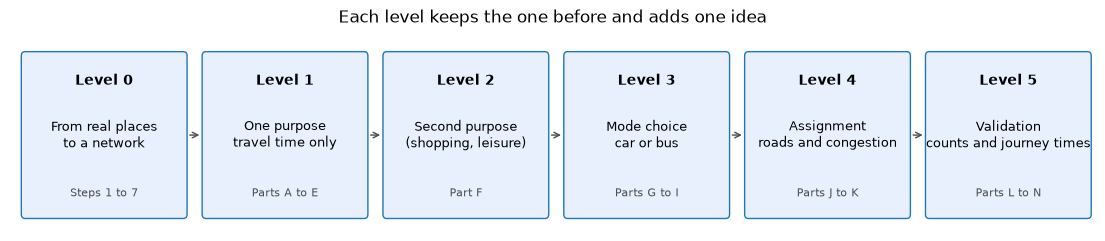

In [182]:
from matplotlib.patches import FancyBboxPatch

levels = [
    ("Level 0", "From real places\nto a network", "Steps 1 to 7"),
    ("Level 1", "One purpose\ntravel time only", "Parts A to E"),
    ("Level 2", "Second purpose\n(shopping, leisure)", "Part F"),
    ("Level 3", "Mode choice\ncar or bus", "Parts G to I"),
    ("Level 4", "Assignment\nroads and congestion", "Parts J to K"),
    ("Level 5", "Validation\ncounts and journey times", "Parts L to N"),
]
fig, ax = plt.subplots(figsize=(14, 2.6))
for k, (name, what, parts) in enumerate(levels):
    x = k * 2.4
    ax.add_patch(FancyBboxPatch((x, 0), 2.1, 1.9, boxstyle="round,pad=0.05",
                                facecolor="#e8f0fe", edgecolor="tab:blue"))
    ax.text(x + 1.05, 1.6, name, ha="center", va="center", fontsize=10, weight="bold")
    ax.text(x + 1.05, 0.95, what, ha="center", va="center", fontsize=9)
    ax.text(x + 1.05, 0.25, parts, ha="center", va="center", fontsize=8, color="0.3")
    if k < len(levels) - 1:
        ax.annotate("", xy=(x + 2.35, 0.95), xytext=(x + 2.15, 0.95),
                    arrowprops=dict(arrowstyle="->", color="0.3"))
ax.set_xlim(-0.2, 14.2)
ax.set_ylim(-0.2, 2.2)
ax.axis("off")
ax.set_title("Each level keeps the one before and adds one idea")
plt.show()

# Level 0: from the real world to a network

This level has **no model numbers**. It shows the simplifications that turn real places into zones, nodes and links, and says what each one leaves out. The rest of the notebook starts from the last step.

**Simplifying:** nothing yet. This is the starting picture.

**Adding:** the idea of activities and trips, then zones, nodes and links, one at a time.

**Why:** a model is only as good as the simplifications behind it. If each one is written down, each one can be checked and changed.


### Step 1: the real world

The real world is a set of **places** of different shapes and sizes: homes, a workplace, shops and a school. Nothing in it is a neat square or a single point. A model cannot hold every place, so the next steps simplify it.


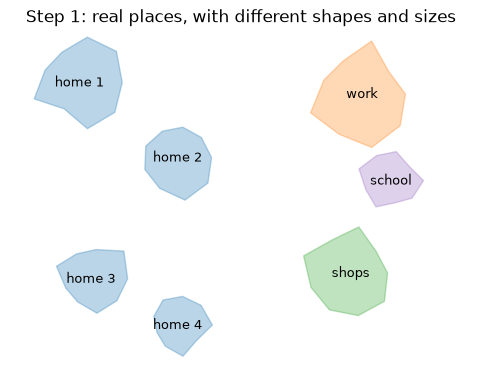

In [183]:
# Made-up real places as irregular shapes, drawn on the same 0 to 8 by 0 to 6 frame as the zone map.
from matplotlib.patches import Polygon, Rectangle

rng = np.random.default_rng(7)   # fixed seed, so the shapes are the same every time the notebook runs

def blob(cx, cy, r, n=9):
    # An irregular outline: a circle with each point pushed in or out a little.
    ang = np.linspace(0, 2 * np.pi, n, endpoint=False)
    rad = r * (1 + 0.25 * rng.uniform(-1, 1, n))
    return np.column_stack([cx + rad * np.cos(ang), cy + rad * np.sin(ang)])

# name: (kind, centre x, centre y, size in km). The kind sets the colour.
PLACES = {
    "home 1": ("home", 1.2, 5.1, 0.7),
    "home 2": ("home", 2.9, 3.8, 0.6),
    "home 3": ("home", 1.4, 1.7, 0.6),
    "home 4": ("home", 2.9, 0.9, 0.5),
    "work":   ("work", 6.1, 4.9, 0.8),
    "school": ("school", 6.6, 3.4, 0.5),
    "shops":  ("shop", 5.9, 1.8, 0.7),
}
COLOUR = {"home": "tab:blue", "work": "tab:orange", "school": "tab:purple", "shop": "tab:green"}
SHAPE = {name: blob(cx, cy, r) for name, (kind, cx, cy, r) in PLACES.items()}

def draw_places(ax, alpha=0.3):
    for name, (kind, cx, cy, r) in PLACES.items():
        ax.add_patch(Polygon(SHAPE[name], closed=True, facecolor=COLOUR[kind], alpha=alpha, edgecolor=COLOUR[kind]))
        ax.text(cx, cy, name, ha="center", va="center", fontsize=9)

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_places(ax, alpha=0.3)
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 1: real places, with different shapes and sizes")
plt.show()


### Step 2: why people travel

People make trips because **activities** are in different places. Someone lives in one place, works in another and shops in a third. A **trip** is a move from one activity to another, and it has a **purpose**: work, shopping, school and so on. Each numbered arrow below is one trip. The table lists them. Level 1 starts with work trips; Level 2 adds shopping and leisure.


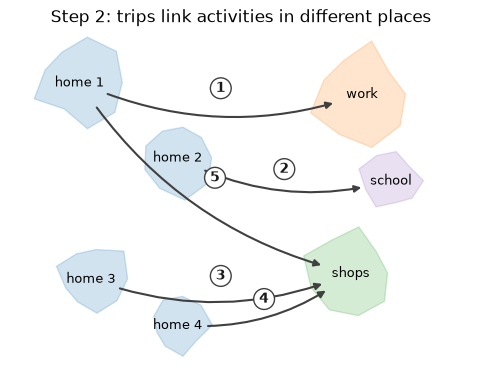

,trip,from,to,purpose
0,1,home 1,work,work
1,2,home 2,school,school
2,3,home 3,shops,shopping
3,4,home 4,shops,shopping
4,5,home 1,shops,shopping


In [184]:
# The same places, joined by numbered arrows: one arrow per trip. The table gives each trip's purpose.
TRIPS = [
    ("home 1", "work", "work"),
    ("home 2", "school", "school"),
    ("home 3", "shops", "shopping"),
    ("home 4", "shops", "shopping"),
    ("home 1", "shops", "shopping"),
]

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_places(ax, alpha=0.2)
for k, (a, b, purpose) in enumerate(TRIPS, start=1):
    (x1, y1), (x2, y2) = PLACES[a][1:3], PLACES[b][1:3]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="0.25", lw=1.5,
                                shrinkA=22, shrinkB=22, connectionstyle="arc3,rad=0.2"))
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    ax.text(mx, my, str(k), fontsize=10, weight="bold", color="0.1", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor="0.25"))
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 2: trips link activities in different places")
plt.show()

pd.DataFrame([{"trip": k, "from": a, "to": b, "purpose": p} for k, (a, b, p) in enumerate(TRIPS, start=1)])


### Step 3: simplification 1, places into zones

Nearby places are grouped into **zones**. The model now works with four zones, A to D, instead of seven places. **What we lose:** the detail inside each zone, such as which home a trip starts from. **What we gain:** a table small enough to check by hand. Where the zone boundaries go is a choice. Here they are straight lines, which is easy to draw and to check. The table below the map shows which zone each place falls in.


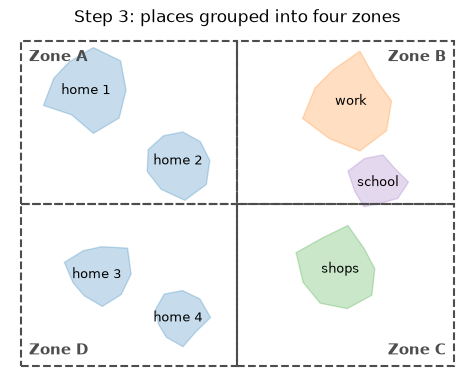

zone
A    home 1, home 2
B      work, school
C             shops
D    home 3, home 4
Name: places in zone, dtype: str

In [185]:
# Group the places into four zones. The boxes are the same zones as the area map in Part A.
def zone_of(x, y):
    # Top row is A (left) and B (right). Bottom row is D (left) and C (right).
    if y >= 3:
        return "A" if x < 4 else "B"
    return "D" if x < 4 else "C"

box = {"A": (0, 3), "B": (4, 3), "C": (4, 0), "D": (0, 0)}   # lower-left corner of each 4 km by 3 km zone
label_at = {"A": (0.15, 5.85, "left", "top"), "B": (7.85, 5.85, "right", "top"),
            "C": (7.85, 0.15, "right", "bottom"), "D": (0.15, 0.15, "left", "bottom")}

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_places(ax, alpha=0.25)
for z, (x, y) in box.items():
    ax.add_patch(Rectangle((x, y), 4, 3, fill=False, linestyle="--", edgecolor="0.3", linewidth=1.5))
    lx, ly, ha, va = label_at[z]
    ax.text(lx, ly, f"Zone {z}", fontsize=11, weight="bold", color="0.3", ha=ha, va=va)
ax.set_xlim(-0.2, 8.2)
ax.set_ylim(-0.2, 6.2)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 3: places grouped into four zones")
plt.show()

zone_table = pd.DataFrame(
    [{"place": name, "zone": zone_of(cx, cy)} for name, (kind, cx, cy, r) in PLACES.items()])
zone_table.groupby("zone")["place"].apply(", ".join).rename("places in zone")


### Step 4: simplification 2, each zone becomes one node

Each zone is shrunk to one point, its **node** (centroid). All of its trips start and end at that point. **What we lose:** where in the zone a trip starts. **What we gain:** one number per pair of zones, for distance and time. The model works out how many trips go between these four points.


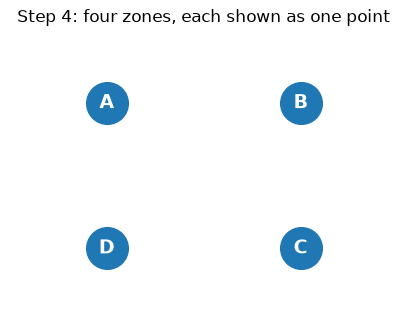

In [186]:
# Each zone as one point (node). Same layout as the area map further down.
pos = POS

fig, ax = plt.subplots(figsize=(5, 4))
for z, (x, y) in pos.items():
    ax.scatter(x, y, s=900, color="tab:blue", zorder=3)
    ax.text(x, y, z, color="white", ha="center", va="center", fontsize=14, weight="bold", zorder=4)
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 4: four zones, each shown as one point")
plt.show()

### Step 5: add the links between zones

Links are the roads between nodes. A trip needs a path of links, so the model needs this picture before it can have times. Still no numbers. Two zones with no line between them have no direct road. B and D is one such pair, so its trips take a longer route (Part A, below).


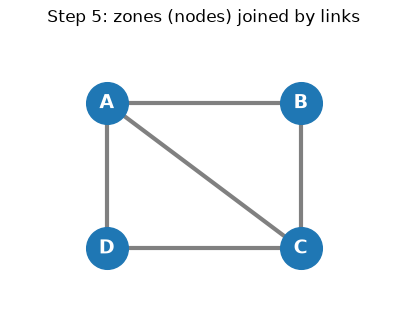

In [187]:
# The same four points, now joined by the five two-way links. No numbers yet.
pos = POS
link_pairs = [("A", "B"), ("B", "C"), ("C", "D"), ("D", "A"), ("A", "C")]

fig, ax = plt.subplots(figsize=(5, 4))
for a, b in link_pairs:
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.plot([x1, x2], [y1, y2], color="0.5", linewidth=3, zorder=1)
for z, (x, y) in pos.items():
    ax.scatter(x, y, s=900, color="tab:blue", zorder=3)
    ax.text(x, y, z, color="white", ha="center", va="center", fontsize=14, weight="bold", zorder=4)
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 5: zones (nodes) joined by links")
plt.show()

### Step 6: give each link a cost

A link needs a number before the model can use it. The first number is the **free-flow time**: how long the link takes when it is empty. Deterrence (Part C) uses it. The second is the **capacity** in vehicles per hour: how many vehicles it can carry. Capacity is not used until Part J, when congestion is added. The figure shows one link, using the A to B values from the links table in Part A.


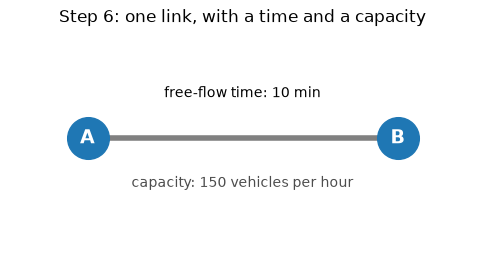

In [188]:
# One link on its own. The values are the A to B row of the links table in Part A.
free_flow_min, capacity_vph = 10, 150

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot([1, 5], [1, 1], color="0.5", linewidth=4, zorder=1)
for x, z in [(1, "A"), (5, "B")]:
    ax.scatter(x, 1, s=900, color="tab:blue", zorder=3)
    ax.text(x, 1, z, color="white", ha="center", va="center", fontsize=14, weight="bold", zorder=4)
ax.text(3, 1.35, f"free-flow time: {free_flow_min} min", ha="center", va="bottom", fontsize=10)
ax.text(3, 0.65, f"capacity: {capacity_vph} vehicles per hour", ha="center", va="top", fontsize=10, color="0.3")
ax.set_xlim(0, 6)
ax.set_ylim(0, 2)
ax.axis("off")
ax.set_title("Step 6: one link, with a time and a capacity")
plt.show()


### Step 7: adding zone size

A zone is an **area**, not a point. A trip inside a zone still takes time, and a bigger zone has longer trips inside it. The toy model uses half the time to the nearest zone for a trip within a zone (Part A, trips within a zone). **Why:** this is the first point where the size of a zone matters, so it is added after nodes and links. The map of zone areas is in Part A, after the links table.


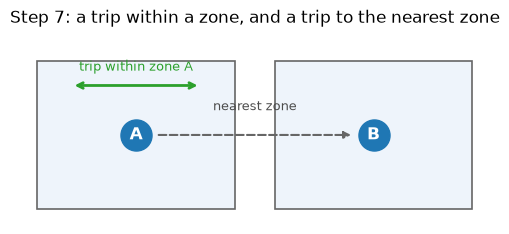

In [189]:
# One zone as an area, with a trip inside it and the trip to the nearest zone.
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.add_patch(Rectangle((0, 0), 4, 3, facecolor="#eef4fb", edgecolor="0.4", linewidth=1.2))     # zone A
ax.add_patch(Rectangle((4.8, 0), 4, 3, facecolor="#eef4fb", edgecolor="0.4", linewidth=1.2))   # nearest zone B
centroid_a, centroid_b = (2, 1.5), (6.8, 1.5)
for (x, y), z in [(centroid_a, "A"), (centroid_b, "B")]:
    ax.scatter(x, y, s=500, color="tab:blue", zorder=3)
    ax.text(x, y, z, color="white", ha="center", va="center", fontsize=12, weight="bold", zorder=4)

# A trip inside zone A (both ends inside the area).
ax.annotate("", xy=(3.3, 2.5), xytext=(0.7, 2.5),
            arrowprops=dict(arrowstyle="<->", color="tab:green", lw=2))
ax.text(2, 2.8, "trip within zone A", ha="center", fontsize=9, color="tab:green")
# The trip to the nearest zone, between the two centroids.
ax.annotate("", xy=(centroid_b[0] - 0.4, 1.5), xytext=(centroid_a[0] + 0.4, 1.5),
            arrowprops=dict(arrowstyle="-|>", color="0.4", lw=1.5, linestyle="--"))
ax.text(4.4, 2.0, "nearest zone", ha="center", fontsize=9, color="0.3")
ax.set_xlim(-0.3, 9.1)
ax.set_ylim(-0.3, 3.6)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Step 7: a trip within a zone, and a trip to the nearest zone")
plt.show()


## What we leave out, for now

| Left out | Why it is simplified | Where it comes back |
|---|---|---|
| Where in a zone a trip starts | One node per zone | Part A, trips within a zone |
| Connectors from centroids to the road network | Toy network | Never in the toy model; real models add them |
| One-way roads | Same time in both directions | Never in the toy model; real networks have them |
| Congestion | Free-flow times only | Level 4, Part J |
| Other trip purposes | Work only | Level 2, Part F |
| Modes other than car and bus | Car and bus only | Never in the toy model |
| Checks against data | Made-up counts and times | Level 5, Parts L to N |
| Time of day | AM peak only, as in the real model | `docs/methodology.md`, Scope |


# Level 1: one purpose, travel time only

At this level there is one trip purpose (home-based work, HBW), one mode, and travel time as the only cost. The four steps are: build the network times, set the trip ends, add deterrence, and balance the trips.

**Simplifying:** the real places become four zones. Each zone is one node. Every trip is work, by one mode, and only travel time counts.

**Adding:** the gravity model and balancing (Furness). This turns productions and attractions into a trip table.

**Why:** it is the smallest model that answers "where do trips go?", and it can be checked by hand.


### The four steps at a glance

The model runs in four steps, one after another. The diagram shows which parts of the notebook do each step. Trip generation is given in this toy model (the productions in Part B), so only the other three steps are built.

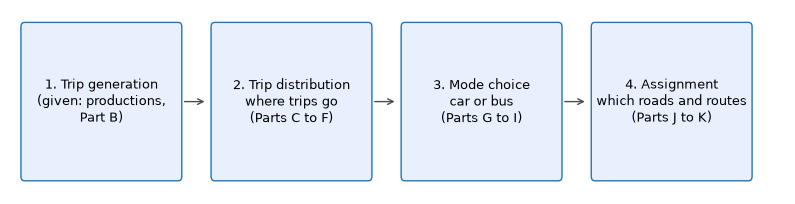

In [190]:
from matplotlib.patches import FancyBboxPatch

steps = [
    "1. Trip generation\n(given: productions,\nPart B)",
    "2. Trip distribution\nwhere trips go\n(Parts C to F)",
    "3. Mode choice\ncar or bus\n(Parts G to I)",
    "4. Assignment\nwhich roads and routes\n(Parts J to K)",
]
fig, ax = plt.subplots(figsize=(10, 2.4))
for k, text in enumerate(steps):
    x = k * 2.6
    ax.add_patch(FancyBboxPatch((x, 0), 2.1, 1.7, boxstyle="round,pad=0.05",
                                facecolor="#e8f0fe", edgecolor="tab:blue"))
    ax.text(x + 1.05, 0.85, text, ha="center", va="center", fontsize=9)
    if k < len(steps) - 1:
        ax.annotate("", xy=(x + 2.5, 0.85), xytext=(x + 2.15, 0.85),
                    arrowprops=dict(arrowstyle="->", color="0.3"))
ax.set_xlim(-0.2, 10.4)
ax.set_ylim(-0.2, 1.9)
ax.axis("off")
plt.show()

### The loop the four steps leave out

The arrows run one way. Trip distribution uses free-flow times, so congestion does not feed back into where people go. The dashed arrow shows the loop a fuller model would close. It is not part of this notebook yet (see Notes).

In [ ]:
from matplotlib.patches import FancyBboxPatch

steps = [
    "1. Trip generation\n(given: productions,\nPart B)",
    "2. Trip distribution\nwhere trips go\n(Parts C to F)",
    "3. Mode choice\ncar or bus\n(Parts G to I)",
    "4. Assignment\nwhich roads and routes\n(Parts J to K)",
]
fig, ax = plt.subplots(figsize=(10, 3.6))
for k, text in enumerate(steps):
    x = k * 2.6
    ax.add_patch(FancyBboxPatch((x, 0.9), 2.1, 1.7, boxstyle="round,pad=0.05",
                                facecolor="#e8f0fe", edgecolor="tab:blue"))
    ax.text(x + 1.05, 1.75, text, ha="center", va="center", fontsize=9)
    if k < len(steps) - 1:
        ax.annotate("", xy=(x + 2.5, 1.75), xytext=(x + 2.15, 1.75),
                    arrowprops=dict(arrowstyle="->", color="0.3"))
# Feedback: congested times go from assignment (box 4) back to distribution (box 2), under the boxes.
x_from, x_to = 3 * 2.6 + 1.05, 1 * 2.6 + 1.05
ax.plot([x_from, x_from], [0.9, 0.45], color="tab:red", linestyle="--")
ax.plot([x_from, x_to], [0.45, 0.45], color="tab:red", linestyle="--")
ax.annotate("", xy=(x_to, 0.9), xytext=(x_to, 0.45),
            arrowprops=dict(arrowstyle="->", color="tab:red", linestyle="--"))
ax.text((x_from + x_to) / 2, 0.2, "congested travel times feed back into distribution\n"
        "(not in this notebook: distribution uses free-flow times)",
        ha="center", va="center", fontsize=8.5, color="tab:red")
ax.set_xlim(-0.2, 10.4)
ax.set_ylim(-0.1, 3.0)
ax.axis("off")
ax.set_title("The four steps, with the feedback loop that is still missing")
plt.show()


## Part A. Network and travel times

**Question.** How long does it take to travel between each pair of zones?

**First principles.** A road network is a set of **nodes** (places) and **links** (roads between them). Each link has a travel time. The time from one zone to another is the total time along the quickest sequence of links between them.

We need three things:

1. **The links:** which zones they connect, and the **free-flow time** (how long a link takes when it is empty).
2. **The capacity** of each link, in vehicles per hour. We need this in Part J.
3. **The shortest time** between every pair of zones.

**Assumption:** links are two-way and take the same time in both directions.

**TAG reference: M3.1 section 2.4 (network structure), listed on contents page 5.** The section text has not been checked yet. The free-flow times and capacities are placeholders.

In [191]:
# Five two-way links between the four zones. Capacities were raised once the work and other
# trips were both assigned: the work-only capacities gave v/c above 2.5 on some links.
links = pd.DataFrame(
    [
        ("A", "B", 10, 150),
        ("B", "C", 12, 125),
        ("C", "D", 8, 250),
        ("D", "A", 15, 150),
        ("A", "C", 20, 100),
    ],
    columns=["from", "to", "free_flow_min", "capacity_vph"],
)
links

,from,to,free_flow_min,capacity_vph
0,A,B,10,150
1,B,C,12,125
2,C,D,8,250
3,D,A,15,150
4,A,C,20,100


### Shortest times between all pairs

**First principles (Floyd–Warshall).** Start with the link times: a zone is 0 minutes from itself, and zones with no direct link are infinitely far apart. Then, for each zone $k$ in turn, check every pair $(i, j)$: is going $i \to k \to j$ quicker than the best time found so far? If so, keep the quicker time.

Any route either goes directly, or passes through some zone. Trying each zone as a possible stop-over covers every route, so the final table holds the shortest times.

In [192]:
n = len(ZONES)
idx = {z: k for k, z in enumerate(ZONES)}

# Direct link times as a matrix. No direct link = infinity. A zone to itself = 0.
link_time = np.full((n, n), np.inf)
np.fill_diagonal(link_time, 0.0)
for _, row in links.iterrows():
    i, j = idx[row["from"]], idx[row["to"]]
    link_time[i, j] = link_time[j, i] = row["free_flow_min"]

# Floyd-Warshall: try each zone k as a stop-over. Record the stop-over used for each pair
# (via), so the route can be rebuilt in the next cell.
best = link_time.copy()
via = np.full((n, n), -1)              # -1 = direct link
for k in range(n):
    for i in range(n):
        for j in range(n):
            if best[i, k] + best[k, j] < best[i, j]:
                best[i, j] = best[i, k] + best[k, j]
                via[i, j] = k

pd.DataFrame(best, index=ZONES, columns=ZONES)

,A,B,C,D
A,0.0,10.0,20.0,15.0
B,10.0,0.0,12.0,20.0
C,20.0,12.0,0.0,8.0
D,15.0,20.0,8.0,0.0


**Free-flow time and shortest time are different things.** Free-flow times are the inputs: one per link, read from the network. Shortest times are results: one per pair of zones, worked out from the links. In this network almost every shortest time is simply the direct link, so the two tables look alike. The table below sets them side by side and shows the route taken. B to D is the one pair with no direct link. Its shortest time of 20 minutes comes from the route B - C - D, and no single link has that time. In a larger network, many more pairs would take a route of several links.

In [193]:
# Compare each zone pair's direct link (free-flow time) with its shortest time, and show the route.
def route(i, j):
    if via[i, j] == -1:
        return [ZONES[i], ZONES[j]]
    k = via[i, j]
    return route(i, k)[:-1] + route(k, j)

rows = []
for i in range(n):
    for j in range(i + 1, n):
        direct = link_time[i, j]
        rows.append({
            "pair": f"{ZONES[i]} to {ZONES[j]}",
            "direct link (min)": "no link" if np.isinf(direct) else direct,
            "shortest (min)": best[i, j],
            "route": " - ".join(route(i, j)),
        })
pd.DataFrame(rows)

,pair,direct link (min),shortest (min),route
0,A to B,10.0,10.0,A - B
1,A to C,20.0,20.0,A - C
2,A to D,15.0,15.0,A - D
3,B to C,12.0,12.0,B - C
4,B to D,no link,20.0,B - C - D
5,C to D,8.0,8.0,C - D


### Zone areas and links on the map

Each zone is an **area**, shown as a rectangle. Its **centroid** (the dot) stands for the whole zone: its trips start and end there. Lines join centroids. Real models also connect each centroid to the road network, which this toy model leaves out.

The links show free-flow time, distance between centroids, and capacity. The thicker the line, the more traffic it can carry.

The zone areas are **made up**: each zone is 4 km by 3 km, so 12 km². Area matters because a bigger zone has longer trips inside it, which is why intrazonal time depends on zone size (TAG M2.1 section 2.4.4).


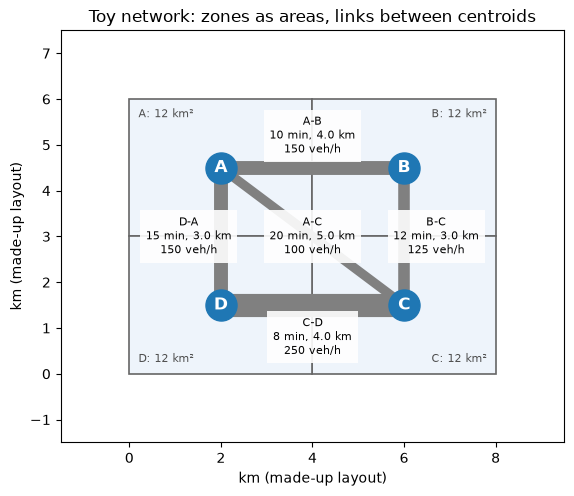

,from,to,free_flow_min,capacity_vph,distance_km
0,A,B,10,150,4.0
1,B,C,12,125,3.0
2,C,D,8,250,4.0
3,D,A,15,150,3.0
4,A,C,20,100,5.0


In [194]:
# Made-up zone areas (km). Each zone is a 4 km by 3 km rectangle, given by its lower-left corner.
W, H = 4, 3
zone_corner = {"A": (0, 3), "B": (4, 3), "C": (4, 0), "D": (0, 0)}
pos = POS   # centroids, as defined in Setup
centre = (4, 3)                                                            # middle of the study area

links_map = links.copy()
links_map["distance_km"] = [
    round(float(np.hypot(pos[a][0] - pos[b][0], pos[a][1] - pos[b][1])), 1)
    for a, b in zip(links_map["from"], links_map["to"])
]

from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for z, (x, y) in zone_corner.items():
    ax.add_patch(Rectangle((x, y), W, H, facecolor="#eef4fb", edgecolor="0.4", linewidth=1.2, zorder=0))
# Area labels in each zone's outer corner, away from the links.
ax.text(0.2, 5.8, f"A: {W * H} km²", fontsize=8, color="0.3", va="top", ha="left", zorder=1)
ax.text(7.8, 5.8, f"B: {W * H} km²", fontsize=8, color="0.3", va="top", ha="right", zorder=1)
ax.text(7.8, 0.2, f"C: {W * H} km²", fontsize=8, color="0.3", va="bottom", ha="right", zorder=1)
ax.text(0.2, 0.2, f"D: {W * H} km²", fontsize=8, color="0.3", va="bottom", ha="left", zorder=1)

for _, row in links_map.iterrows():
    (x1, y1), (x2, y2) = pos[row["from"]], pos[row["to"]]
    ax.plot([x1, x2], [y1, y2], color="0.5", linewidth=row["capacity_vph"] / 15,
            solid_capstyle="round", zorder=2)
    # Push each link label away from the centre, so it sits beside its line rather than on it.
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    dx, dy = mx - centre[0], my - centre[1]
    norm = np.hypot(dx, dy)
    if norm > 0:
        mx, my = mx + 0.7 * dx / norm, my + 0.7 * dy / norm
    label = (f"{row['from']}-{row['to']}\n"
             f"{row['free_flow_min']} min, {row['distance_km']} km\n"
             f"{row['capacity_vph']} veh/h")
    ax.text(mx, my, label, ha="center", va="center", fontsize=8, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))

for z, (x, y) in pos.items():
    ax.scatter(x, y, s=500, color="tab:blue", zorder=3)
    ax.text(x, y, z, color="white", ha="center", va="center", fontsize=12, weight="bold", zorder=5)

ax.set_aspect("equal")
ax.set_xlim(-1.5, 9.5)
ax.set_ylim(-1.5, 7.5)
ax.set_xlabel("km (made-up layout)")
ax.set_ylabel("km (made-up layout)")
ax.set_title("Toy network: zones as areas, links between centroids")
plt.show()

links_map

### Trips within a zone

**First principles.** A trip from a zone to itself still takes time (you cross the zone), but less than a trip to the next zone. A common rule of thumb is half the time to the nearest other zone.

A zero would make intrazonal trips look free, so the deterrence function (Part C) would treat them as the most attractive trips in the model.

**TAG reference: M2.2 section 5.2.28, PDF p. 22.**
> "A measure of intra-zonal costs should be estimated. It is common to assume a value based on the cost to adjacent zones. Some models for example adopt half the lowest inter-zonal cost, often imposing a cap that maintains costs at or below mean trip distances for large zones."

This is the rule the notebook uses. The cap matters for large zones, which this toy model does not need.

**TAG reference: M2.1 section 2.4.4, PDF p. 17.**
> "for large zones it is important that the average intrazonal costs are as realistic as possible."

Zone size matters for trips within a zone. This is why the map shows zone areas.

In [195]:
# Travel time matrix c (minutes). Intrazonal time = half the time to the nearest other zone.
c = best.copy()
for i in range(n):
    nearest = min(best[i, j] for j in range(n) if j != i)
    c[i, i] = nearest / 2

assert np.allclose(c, c.T), "the matrix should be symmetric"

pd.DataFrame(c, index=ZONES, columns=ZONES)

,A,B,C,D
A,5.0,10.0,20.0,15.0
B,10.0,5.0,12.0,20.0
C,20.0,12.0,4.0,8.0
D,15.0,20.0,8.0,4.0


## Part B. Productions and attractions (HBW)

**Question.** How many work trips start and end in each zone?

**First principles.** Every trip has one start and one end. The total leaving every zone must equal the total arriving at every zone:

$$\sum_i P_i = \sum_j A_j$$

- **Productions** $P_i$: trips starting in zone $i$. For work trips these come from the workers who live there.
- **Attractions** $A_j$: trips ending in zone $j$. For work trips these come from the jobs there.

First guesses for attractions rarely add up to the productions total, so we scale them:

$$A_j = A_j^{\text{raw}} \cdot \frac{\sum_i P_i}{\sum_k A_k^{\text{raw}}}$$

We keep the productions and scale the attractions, because productions come from household data and are usually more reliable.

**TAG reference.** Not checked. Trip generation is outside this toy model. The productions and attractions are placeholders, to be sourced in the real model.

In [196]:
P_w = np.array([400.0, 300.0, 200.0, 100.0])      # HBW productions, trips/h
A_raw = np.array([550.0, 150.0, 150.0, 250.0])    # first-guess HBW attractions, trips/h

A_w = A_raw * (P_w.sum() / A_raw.sum())

print("sum of P_w    =", P_w.sum())
print("sum of A_raw  =", A_raw.sum())
print("sum of A_w    =", A_w.sum())
print("A_w           =", A_w)
assert np.isclose(P_w.sum(), A_w.sum())

sum of P_w    = 1000.0
sum of A_raw  = 1100.0
sum of A_w    = 1000.0
A_w           = [500.     136.3636 136.3636 227.2727]


### Productions and attractions on the map

Orange arrows show **productions**: work trips leaving each zone. Green arrows show **attractions**: work trips arriving at each zone. Each value sits next to its arrow. The two totals are equal, as the equation above requires. The values are placeholders.

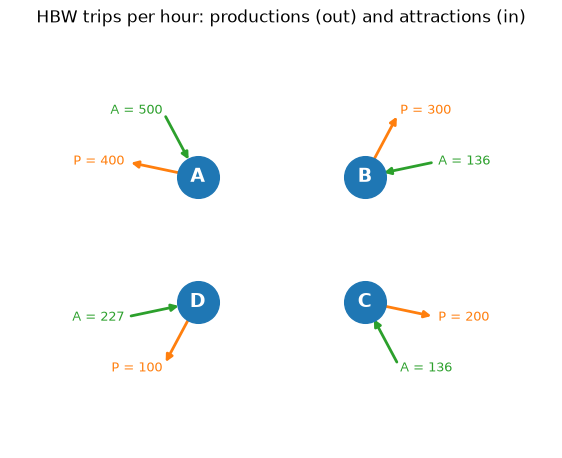

In [197]:
# Productions leave each zone (orange, outward). Attractions arrive at each zone (green, inward).
pos = POS
centre = np.array([4.0, 3.0])

def turn(v, deg):
    t = np.radians(deg)
    return np.array([v[0] * np.cos(t) - v[1] * np.sin(t), v[0] * np.sin(t) + v[1] * np.cos(t)])

fig, ax = plt.subplots(figsize=(7, 5.5))
for k, z in enumerate(ZONES):
    p = np.array(pos[z], dtype=float)
    out_dir = (p - centre) / np.linalg.norm(p - centre)
    prod_dir = turn(out_dir, 25)      # production arrow leaves the zone
    attr_dir = turn(out_dir, -25)     # attraction arrow arrives at the zone

    ax.annotate("", xy=p + 1.7 * prod_dir, xytext=p + 0.4 * prod_dir,
                arrowprops=dict(arrowstyle="-|>", color="tab:orange", lw=2))
    ax.text(*(p + 1.8 * prod_dir), f"P = {P_w[k]:.0f}", color="tab:orange",
            ha="left" if prod_dir[0] > 0 else "right", va="center", fontsize=9)

    ax.annotate("", xy=p + 0.4 * attr_dir, xytext=p + 1.7 * attr_dir,
                arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=2))
    ax.text(*(p + 1.8 * attr_dir), f"A = {A_w[k]:.0f}", color="tab:green",
            ha="left" if attr_dir[0] > 0 else "right", va="center", fontsize=9)

    ax.scatter(p[0], p[1], s=900, color="tab:blue", zorder=3)
    ax.text(p[0], p[1], z, color="white", ha="center", va="center", fontsize=14, weight="bold", zorder=4)

ax.set_xlim(-2.5, 10.5)
ax.set_ylim(-2, 8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("HBW trips per hour: productions (out) and attractions (in)")
plt.show()

## Part C. Deterrence: how travel time puts people off

**Question.** How much weight should a pair of zones get, given the travel time between them?

**First principles.** Two ideas:

- People prefer shorter trips, so the weight should fall as travel time rises.
- Each extra minute should put off the same *share* of trips, not the same number. Going from 10 to 20 minutes should cut trips by the same percentage as going from 40 to 50.

A function with that property is the exponential:

$$f(c) = e^{-\beta c}$$

- Each extra minute multiplies the weight by $e^{-\beta}$, a fixed fraction.
- $f(0) = 1$: no travel time, no deterrence.
- $f$ is never negative, so a trip count cannot go below zero.
- $\beta$ (per minute) sets how fast the weight falls. A bigger $\beta$ means people give up on long trips sooner.

We use $\beta_w = 0.05$ for work. A 9-minute trip keeps about 64% of its weight, and a 60-minute trip keeps about 5%. There is no survey data here to calibrate against, so this is a placeholder. Plan Phase 3 calibrates $\beta$ against the observed trip length distribution.

**TAG reference: M2.1 section 4.9.14, PDF p. 52.**
> "It is expected that the model form will generally be logit."

TAG expects a logit model form. The exponential used here is one of the deterrence functions TAG describes in Appendix C.

**TAG reference: M2.2 section 5.2.31, PDF p. 23.**
> "For the calibration of the deterrence function, it is usually necessary to use a representation of TCD produced from internal zones only to test the model fit."

TAG says to calibrate the deterrence function against observed data. The beta values here are placeholders until that data is in the model.

In [198]:
beta_w = 0.05   # per minute, HBW (placeholder)

def deterrence(t, beta):
    return np.exp(-beta * t)

F_w = deterrence(c, beta_w)   # F_w[i, j] = f(c_ij)
pd.DataFrame(F_w, index=ZONES, columns=ZONES).round(3)

,A,B,C,D
A,0.779,0.607,0.368,0.472
B,0.607,0.779,0.549,0.368
C,0.368,0.549,0.819,0.670
D,0.472,0.368,0.670,0.819


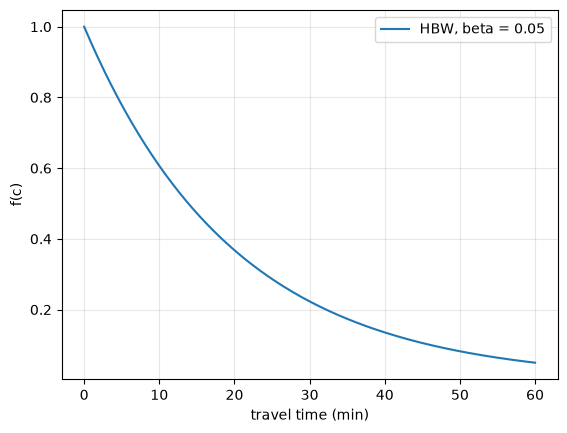

In [199]:
t = np.linspace(0, 60, 200)
plt.plot(t, deterrence(t, beta_w), label=f"HBW, beta = {beta_w}")
plt.xlabel("travel time (min)")
plt.ylabel("f(c)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Part D. The first guess: unconstrained gravity

**Question.** If trips only depended on size and distance, how many would there be?

**First principles.** A zone is more likely to send and receive trips if it is big. A pair of zones is more likely to trade trips if it is close. Multiply the three things together:

$$T^0_{ij} = P_i \, A_j \, f(c_{ij})$$

This is Newton's idea of gravity: two bodies attract in proportion to their masses and fall off with distance.

**Problem.** Nothing forces the row totals to equal $P_i$ or the column totals to equal $A_j$. Part E fixes that.

The numbers below look far too big, and that is expected. Multiplying a production (hundreds) by an attraction (hundreds) gives tens of thousands before the deterrence factor is applied. The balancing factors in Part E shrink them back to the right totals.

**TAG reference: M2.1 section 4.9.14, PDF p. 52** (quoted in Part C). The unbalanced totals are a first guess, not a TAG parameter.

In [200]:
T0 = P_w[:, None] * A_w[None, :] * F_w   # T0[i, j] = P_i * A_j * f(c_ij)

print("row sums:    ", T0.sum(axis=1).round(1), "  target P:", P_w)
print("column sums: ", T0.sum(axis=0).round(1), "  target A:", A_w.round(1))

row sums:     [251852.2 170373.7 104553.6  56383.1]   target P: [400. 300. 200. 100.]
column sums:  [307146.   84927.7  73987.3 117101.7]   target A: [500.  136.4 136.4 227.3]


## Part E. Balancing the trips (Furness method)

**Question.** How do we adjust the first guess so that every zone sends out exactly $P_i$ trips and receives exactly $A_j$ trips?

**First principles.** Multiply each row by a number $a_i$ and each column by a number $b_j$:

$$T_{ij} = a_i \, b_j \, P_i \, A_j \, f(c_{ij})$$

We need two constraints:

- Row: $\sum_j T_{ij} = P_i$
- Column: $\sum_i T_{ij} = A_j$

Take the row constraint and solve for $a_i$, holding the $b$s fixed:

$$\sum_j a_i \, b_j \, P_i \, A_j \, f(c_{ij}) = P_i \quad\Rightarrow\quad a_i = \frac{1}{\sum_j b_j \, A_j \, f(c_{ij})}$$

The column constraint gives the same kind of rule for $b_j$:

$$b_j = \frac{1}{\sum_i a_i \, P_i \, f(c_{ij})}$$

Each rule needs the other set of factors, so we cannot solve them at once. The **Furness method** alternates between them:

1. Start with $a_i = 1$ and $b_j = 1$.
2. Update every $a_i$ with the row rule.
3. Update every $b_j$ with the column rule.
4. Check how much the row and column totals changed since the last pass.
5. Stop when the largest change is below a tolerance (0.1%).

**Guard.** A zero production or attraction makes a division by zero, so the function refuses those inputs.

**TAG reference: M2.1 section 4.9.12, PDF p. 51.**
> "doubly constrained models should be used for commuting and education."

Work trips (HBW) are doubly constrained here, which matches TAG.

The 0.1% tolerance is ours. The 0.1% in TAG M3.1 Table 4 (PDF p. 37) is for assignment convergence, not for balancing.

In [201]:
def furness(P, A, F, tol=1e-3, max_iter=100):
    """Doubly constrained gravity model. Returns the trip matrix T, the factors a and b, and the history of each iteration."""
    assert np.all(P > 0) and np.all(A > 0), "zero productions or attractions cause division by zero"
    a = np.ones(len(P))
    b = np.ones(len(A))
    prev_row = prev_col = None
    history = []                      # (iteration, change, error), for the convergence chart
    for it in range(1, max_iter + 1):
        a = 1.0 / (F @ (b * A))          # row rule
        b = 1.0 / (F.T @ (a * P))        # column rule
        T = a[:, None] * b[None, :] * P[:, None] * A[None, :] * F
        row, col = T.sum(axis=1), T.sum(axis=0)
        error = max(np.max(np.abs(row / P - 1)), np.max(np.abs(col / A - 1)))
        if prev_row is None:
            change = np.nan
        else:
            change = max(np.max(np.abs(row / prev_row - 1)), np.max(np.abs(col / prev_col - 1)))
        print(f"iteration {it:2d}: largest change in totals {change:.6f}   error vs targets {error:.6f}")
        history.append((it, change, error))
        if prev_row is not None and change < tol:
            break
        prev_row, prev_col = row, col
    return T, a, b, history

In [202]:
T_w, a_w, b_w, furness_hist = furness(P_w, A_w, F_w, tol=1e-3)
print()
print("a_w =", a_w)
print("b_w =", b_w)

iteration  1: largest change in totals nan   error vs targets 0.023819
iteration  2: largest change in totals 0.022187   error vs targets 0.001240
iteration  3: largest change in totals 0.001167   error vs targets 0.000072
iteration  4: largest change in totals 0.000067   error vs targets 0.000004

a_w = [0.0016 0.0018 0.0019 0.0017]
b_w = [0.959  0.9313 1.0512 1.1212]


### Furness converging

The change in totals and the error against the targets both fall each iteration. Stop when the change is below the red line (0.1%).

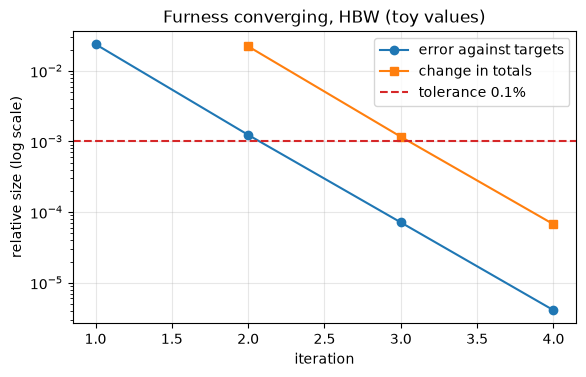

In [203]:
its = [h[0] for h in furness_hist]
errors = [h[2] for h in furness_hist]
changes = [h[1] for h in furness_hist[1:]]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(its, errors, marker="o", label="error against targets")
ax.semilogy(its[1:], changes, marker="s", label="change in totals")
ax.axhline(1e-3, color="tab:red", linestyle="--", label="tolerance 0.1%")
ax.set_xlabel("iteration")
ax.set_ylabel("relative size (log scale)")
ax.set_title("Furness converging, HBW (toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### The trip matrix as a picture

Each cell is the number of trips from one zone (row) to another (column). The diagonal is trips that start and end in the same zone. Darker cells carry more trips.

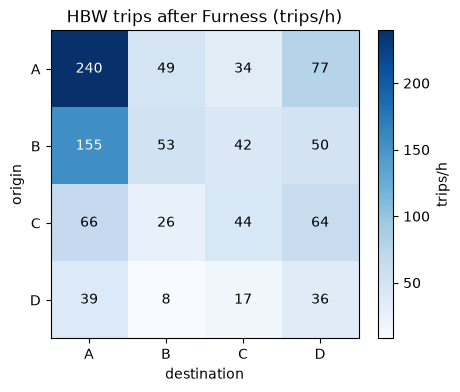

In [204]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(T_w, cmap="Blues")
ax.set_xticks(range(n), ZONES)
ax.set_yticks(range(n), ZONES)
ax.set_xlabel("destination")
ax.set_ylabel("origin")
for i in range(n):
    for j in range(n):
        dark = T_w[i, j] > 0.6 * T_w.max()
        ax.text(j, i, f"{T_w[i, j]:.0f}", ha="center", va="center", color="white" if dark else "black")
ax.set_title("HBW trips after Furness (trips/h)")
fig.colorbar(im, ax=ax, label="trips/h")
plt.show()

In [205]:
print("row sums:    ", T_w.sum(axis=1).round(2), "  target P:", P_w)
print("column sums: ", T_w.sum(axis=0).round(2), "  target A:", A_w.round(2))
pd.DataFrame(T_w, index=ZONES, columns=ZONES).round(1)

row sums:     [400. 300. 200. 100.]   target P: [400. 300. 200. 100.]
column sums:  [500.   136.36 136.36 227.27]   target A: [500.   136.36 136.36 227.27]


,A,B,C,D
A,239.6,49.4,33.8,77.2
B,155.2,52.8,42.0,50.0
C,66.0,26.1,43.9,63.9
D,39.2,8.1,16.6,36.1


### Before and after balancing

The left chart is the first guess: its row totals are far from the targets. The right chart is after Furness: each row total now matches its production.

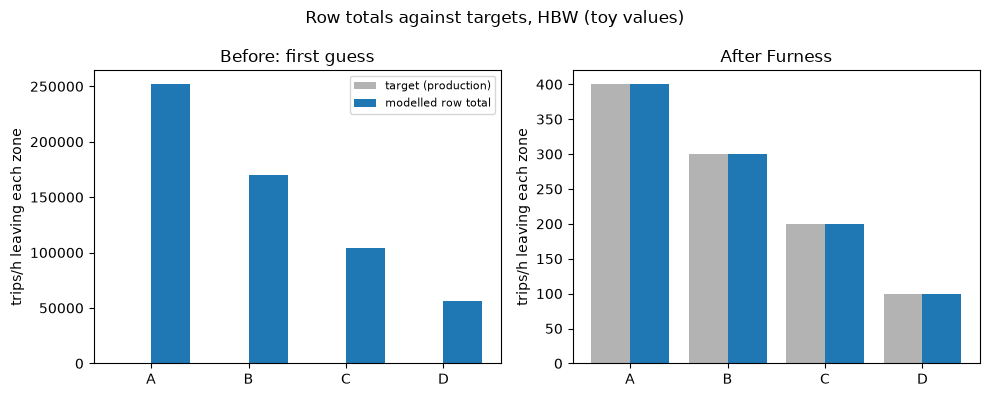

In [206]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(n)
for ax, row_sums, title in [(axes[0], T0.sum(axis=1), "Before: first guess"),
                            (axes[1], T_w.sum(axis=1), "After Furness")]:
    ax.bar(x - 0.2, P_w, width=0.4, color="0.7", label="target (production)")
    ax.bar(x + 0.2, row_sums, width=0.4, color="tab:blue", label="modelled row total")
    ax.set_xticks(x, ZONES)
    ax.set_ylabel("trips/h leaving each zone")
    ax.set_title(title)
axes[0].legend(fontsize=8)
fig.suptitle("Row totals against targets, HBW (toy values)")
plt.tight_layout()
plt.show()

### Checking the trip pattern: trip length distribution

**First principles.** Totals matching is not enough. The trips should also be the right length. We group trips into travel time bands and compare the shares. The **mean trip length** is the average time per trip, weighted by how many trips there are:

$$\bar{c} = \frac{\sum_{i,j} T_{ij} \, c_{ij}}{\sum_{i,j} T_{ij}}$$

If the shares or the mean are wrong, the deterrence $\beta$ is wrong (Part C). This is how $\beta$ gets tuned against data later.

**TAG reference: M2.2 section 5.2.31, PDF p. 23** (quoted in Part C). This check compares the trip-length pattern with observed data. The toy model has no observed data, so this is not yet a TAG test.

In [207]:
BANDS = [0, 10, 20, 30, np.inf]
BAND_LABELS = ["0-10 min", "10-20 min", "20-30 min", "30+ min"]

def trip_length_summary(T, c):
    """Share of trips in each travel time band, and the mean trip length (min)."""
    shares = []
    for lo, hi in zip(BANDS[:-1], BANDS[1:]):
        in_band = (c >= lo) & (c < hi)
        shares.append(T[in_band].sum() / T.sum())
    mean = (T * c).sum() / T.sum()
    return pd.Series(shares, index=BAND_LABELS, name="share of trips").round(3), round(mean, 2)

shares_w, mean_w = trip_length_summary(T_w, c)
print("HBW mean trip length (min):", mean_w)
shares_w

HBW mean trip length (min): 10.19


0-10 min     0.453
10-20 min    0.389
20-30 min    0.158
30+ min      0.000
Name: share of trips, dtype: float64

# Level 2: a second purpose, singly constrained

Now we add home-based other trips (HBO): shopping, leisure and personal business. Two things change:

- Shoppers choose where to go, so their attractions are only **relative weights**, not fixed totals.
- Shoppers tolerate shorter trips than commuters, so they get a larger $\beta$.

This needs a **singly constrained** model: the origins are fixed, the destinations are not.

**Simplifying:** the model keeps the same four zones and the same deterrence form. Nothing is removed.

**Adding:** a second purpose, home-based other (shopping and leisure). It gets its own deterrence and its own balancing. The balancing is singly constrained, because its trip ends are not balanced by household data.

**Why:** work trips are only part of the trips. Other trips go to different places, so one purpose would misstate where trips go.


## Part F. Singly constrained gravity (HBO)

**First principles.** Drop the column rule. Keep the row rule, and let each destination's weight $W_j$ set its share:

$$T_{ij} = a_i \, P_i \, W_j \, f(c_{ij}), \qquad a_i = \frac{1}{\sum_j W_j \, f(c_{ij})}$$

The row rule gives $a_i$ directly, so **no iteration is needed**. The column totals come out wherever they fall, and we check them afterwards rather than forcing them.

**Why this matters.** Doubly constrained is for trips with a fixed start and a fixed end, like work. Singly constrained is for trips where the destination is a choice, like shopping.

**TAG reference: M2.1 section 4.9.12, PDF p. 51.**
> "Other purposes such as shopping, social and leisure trips are typically modelled as singly production-end constrained."

Shopping (HBO) is singly constrained here, which matches TAG. TAG describes the attraction side as trip-end factors, and our weights are a simpler version.

In [208]:
def singly_constrained(P, W, F):
    """Each row sums to P_i. W_j are relative attraction weights, not trip totals."""
    assert np.all(P > 0) and np.all(W > 0), "zero productions or weights cause division by zero"
    a = 1.0 / (F @ W)                       # one pass: no iteration
    T = a[:, None] * P[:, None] * W[None, :] * F
    return T, a

P_o = np.array([300.0, 250.0, 200.0, 150.0])   # HBO productions, trips/h
W_o = np.array([2.0, 1.0, 1.5, 1.0])           # HBO attraction weights (relative, not trips)
beta_o = 0.10                                   # per minute: shoppers give up sooner

F_o = deterrence(c, beta_o)
T_o, a_o = singly_constrained(P_o, W_o, F_o)

print("row sums:", T_o.sum(axis=1).round(2), "  target P_o:", P_o)
print("column sums (not forced):", T_o.sum(axis=0).round(1))

row sums: [300. 250. 200. 150.]   target P_o: [300. 250. 200. 150.]
column sums (not forced): [338.1 173.8 240.6 147.4]


In [209]:
shares_o, mean_o = trip_length_summary(T_o, c)
print("HBO mean trip length (min):", mean_o, "   HBW mean trip length (min):", mean_w)
pd.DataFrame({"HBW share": shares_w, "HBO share": shares_o})

HBO mean trip length (min): 8.85    HBW mean trip length (min): 10.19


,HBW share,HBO share
0-10 min,0.453,0.565
10-20 min,0.389,0.341
20-30 min,0.158,0.095
30+ min,0.000,0.000


### Deterrence and trip length, both purposes

Left: shoppers' weight falls faster with time (larger $\beta$). Right: so their trips are shorter. Both use the same time bands as the trip-length check in Part E.

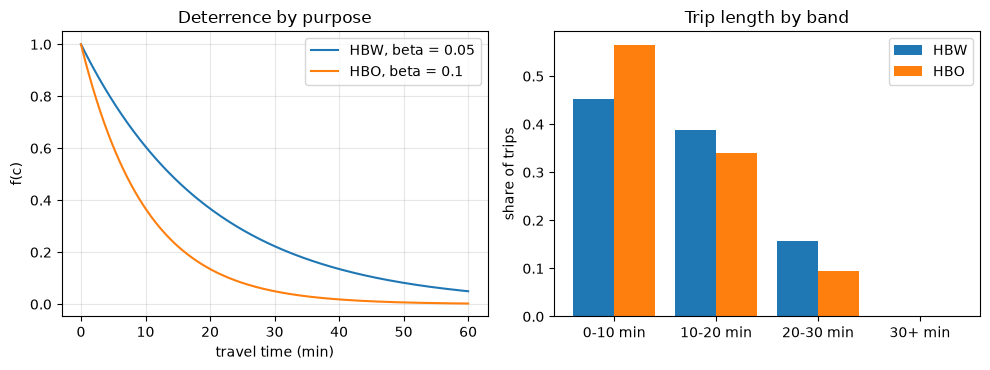

In [210]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
t = np.linspace(0, 60, 200)
ax1.plot(t, deterrence(t, beta_w), label=f"HBW, beta = {beta_w}")
ax1.plot(t, deterrence(t, beta_o), label=f"HBO, beta = {beta_o}")
ax1.set_xlabel("travel time (min)")
ax1.set_ylabel("f(c)")
ax1.set_title("Deterrence by purpose")
ax1.grid(alpha=0.3)
ax1.legend()

x = np.arange(len(BAND_LABELS))
ax2.bar(x - 0.2, shares_w.values, width=0.4, label="HBW")
ax2.bar(x + 0.2, shares_o.values, width=0.4, label="HBO")
ax2.set_xticks(x, BAND_LABELS)
ax2.set_ylabel("share of trips")
ax2.set_title("Trip length by band")
ax2.legend()
plt.tight_layout()
plt.show()

In [211]:
# Total trips across both purposes. Mode choice and assignment use this total.
T_all = T_w + T_o
print("total trips/h, HBW + HBO:", T_all.sum().round(1))
pd.DataFrame(T_all, index=ZONES, columns=ZONES).round(1)

total trips/h, HBW + HBO: 1900.0


,A,B,C,D
A,420.9,104.4,64.2,110.6
B,250.5,131.4,100.5,67.6
C,92.7,55.8,143.2,108.3
D,74.0,18.6,69.1,88.3


### Where the trips go

Each line joins two zones. Its width shows the trips in both directions, so thicker lines carry more trips. Trips within a zone are not drawn.

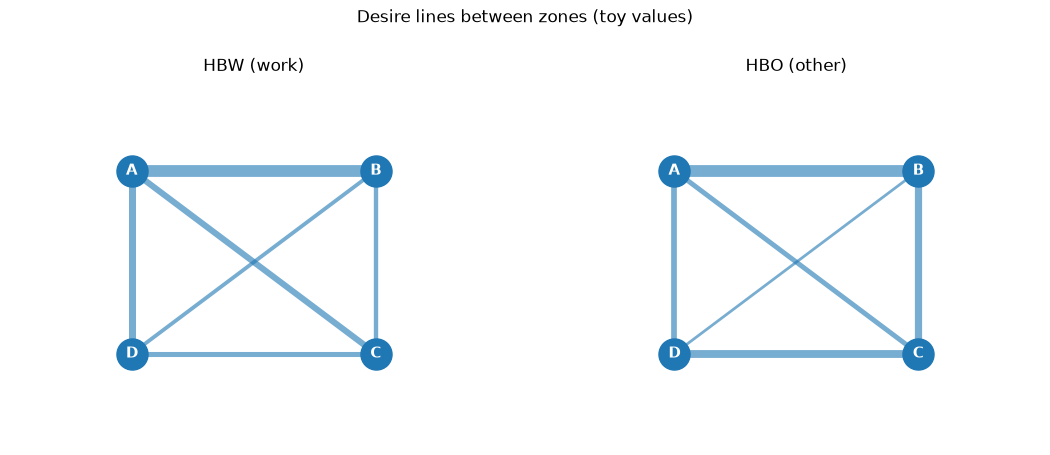

In [212]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, T, title in [(axes[0], T_w, "HBW (work)"), (axes[1], T_o, "HBO (other)")]:
    two_way = T + T.T
    scale = two_way[np.triu_indices(n, 1)].max()
    for a_i in range(n):
        for b_i in range(a_i + 1, n):
            (x1, y1), (x2, y2) = POS[ZONES[a_i]], POS[ZONES[b_i]]
            ax.plot([x1, x2], [y1, y2], color="tab:blue", alpha=0.6,
                    linewidth=0.5 + 8 * two_way[a_i, b_i] / scale)
    for z, (x, y) in POS.items():
        ax.scatter(x, y, s=500, color="tab:blue", zorder=3)
        ax.text(x, y, z, color="white", ha="center", va="center", fontsize=11, weight="bold", zorder=4)
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
fig.suptitle("Desire lines between zones (toy values)")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# Level 3: mode choice

Now we split trips between car and bus. Three new ideas:

1. **Car availability.** Some households have no car, so for them car is not an option.
2. **Money costs and walk/wait weights.** Costs are turned into minutes, and walking and waiting count for more than in-vehicle time.
3. **Calibration.** The logit has a constant for bus. We do not guess it: we adjust it until the modelled car share matches an observed target.

**TAG reference: M2.1 section 4.2, PDF p. 34.**
> "Most variable demand models use some form of "hierarchical logit" formulation (introduced in section 4.2)"

Our mode choice is one logit between car and bus. That is a simplified version of the hierarchical logit TAG describes.

**Simplifying:** only car and bus are modelled. Money and time are turned into one cost in minutes.

**Adding:** car availability, money and walk and wait times, and a logit split with a bus constant calibrated to an observed car share.

**Why:** trips use different modes. Without a split, every trip would load the roads and bus services would have no effect.


## Part G. Car availability segments

**First principles.** The mode choice depends on what a person can use. A zero-car household cannot choose car, so its trips are all bus (or walk). We split the work and other trips by household segment before choosing modes.

Here both zero-car shares are made-up placeholders: one for work trips, one for other trips. The plan (Phase 2) takes it from Census TS045, and treats it as the main driver of mode choice.

**TAG reference.** Not checked. The plan cites the Census TS045 table for the zero-car share. The 30% is a placeholder.

In [213]:
zero_car_share_w = 0.30   # placeholder: share of HBW trips made by zero-car households
zero_car_share_o = 0.30   # placeholder: share of HBO trips made by zero-car households (same value until sourced)

# Each purpose is split by car availability, then the two are added together.
T_own = (1 - zero_car_share_w) * T_w + (1 - zero_car_share_o) * T_o   # car-owning households: car is an option
T_zero = zero_car_share_w * T_w + zero_car_share_o * T_o              # zero-car households: car is not an option

print("car-owning trips/h (HBW + HBO):", T_own.sum().round(1))
print("zero-car trips/h (HBW + HBO):  ", T_zero.sum().round(1))
print("check: own + zero = all trips?", np.allclose(T_own + T_zero, T_all))


car-owning trips/h (HBW + HBO): 1330.0
zero-car trips/h (HBW + HBO):   570.0
check: own + zero = all trips? True


## Part H. Generalised cost in minutes

**First principles.** People do not only care about time. Every cost is converted into minutes, so one number describes each option:

$$GC = \text{in-vehicle time} + w_{\text{walk}} \cdot \text{walk time} + w_{\text{wait}} \cdot \text{wait time} + \frac{\text{money cost}}{\text{value of time}}$$

- **Value of time** (£ per minute) converts money into minutes. This is a placeholder of £12 per hour. The method is in TAG unit A1-3. The values are in the TAG data book, Table A1.3.2.
- **Walk and wait weights** are 2.0 for walking and 1.0 for waiting. People dislike walking and waiting more than sitting in a vehicle. The plan (Phase 4) asks us to record the weight we choose.

**The two options:**

- **Car:** in-vehicle time is $c_{ij}$. Money cost is parking and fuel, £1.50 (placeholder).
- **Bus:** in-vehicle time is 1.1 times the car time, because buses stop more (placeholder). It has a 3-minute walk to the stop, weighted 2.0, and a 4-minute wait, weighted 1.0. Money cost is the £1.80 fare.

**TAG reference: M3.2 section 2.7.5, PDF p. 18.**
> "In-VehicleTime * in-vehicle time factor + Fare / Value of Time +"

The notebook uses this form, with walk and wait weights and a bus in-vehicle factor.

**Weights: M3.2 Table 1, PDF p. 20** ("Recommended Generalised Cost Weights and Penalties"). Walk access 1.5 to 2.0: ours is 2.0, in range. Bus waiting 1: ours is 1.0, in range. In-vehicle time 0.7 to 1.1: ours is 1.1, at the top of the range. The first version of this notebook used 2.0 for waiting and 1.2 for in-vehicle time, both outside the range. The table is hard to read in the extracted text, so check these against the PDF.

**TAG reference: M3.2 section 3.3.3, PDF p. 23.**
> "Fares are converted to time using a value of time parameter in the assignment process."

Fares are turned into minutes by dividing by value of time, as the notebook does.

**TAG reference: M3.1 section 2.8.7, PDF p. 20.**
> "Values of vehicle operating cost and value of time should be derived from TAG unit A1.3 for the base year and for forecasting assignments without amendment."

The method comes from TAG unit A1-3, and the values come from the TAG data book, Table A1.3.2. That table gives values by year, mode and purpose, on different cost bases, so one needs choosing. The £12 per hour is a placeholder until then.

In [214]:
vot = 0.20                 # £ per minute (= £12 per hour, placeholder)
car_money = 1.50           # £ per car trip (placeholder)
bus_fare = 1.80            # £ per bus trip (placeholder)
walk_min, wait_min = 3.0, 4.0
walk_weight = 2.0         # TAG range 1.5 to 2.0
wait_weight = 1.0         # TAG bus waiting weight is 1
bus_ivt_factor = 1.1      # top of TAG range 0.7 to 1.1 (buses stop more)

GC_car = c + car_money / vot
GC_bus = bus_ivt_factor * c + walk_weight * walk_min + wait_weight * wait_min + bus_fare / vot
# GC_bus does not yet include the bus constant (Part I).

print("car money cost in minutes:", round(car_money / vot, 2))
print("bus money cost in minutes:", round(bus_fare / vot, 2))
pd.DataFrame(GC_car, index=ZONES, columns=ZONES).round(1), pd.DataFrame(GC_bus, index=ZONES, columns=ZONES).round(1)

car money cost in minutes: 7.5
bus money cost in minutes: 9.0


(      A     B     C     D
 A  12.5  17.5  27.5  22.5
 B  17.5  12.5  19.5  27.5
 C  27.5  19.5  11.5  15.5
 D  22.5  27.5  15.5  11.5,
       A     B     C     D
 A  24.5  30.0  41.0  35.5
 B  30.0  24.5  32.2  41.0
 C  41.0  32.2  23.4  27.8
 D  35.5  41.0  27.8  23.4)

### What makes up each cost

The bars split the generalised cost of one pair of zones, A to B, into its parts, in minutes. Walking and waiting are weighted, so they take up more of the bus bar than their raw minutes suggest.

In [ ]:
# Generalised cost parts for one pair (A to B), in minutes.
i_ab, j_ab = idx["A"], idx["B"]
parts_car = [("in-vehicle time", c[i_ab, j_ab]), ("money (in minutes)", car_money / vot)]
parts_bus = [("in-vehicle time", bus_ivt_factor * c[i_ab, j_ab]),
             ("walk (weighted)", walk_weight * walk_min),
             ("wait (weighted)", wait_weight * wait_min),
             ("fare (in minutes)", bus_fare / vot)]

colours = {name: plt.cm.Blues(0.3 + 0.12 * k) for k, name in
           enumerate(["in-vehicle time", "money (in minutes)", "walk (weighted)",
                      "wait (weighted)", "fare (in minutes)"])}
fig, ax = plt.subplots(figsize=(8, 3.4))
shown = set()
for row_y, parts, label_text in [(1, parts_car, "car"), (0, parts_bus, "bus, before bus constant")]:
    left = 0.0
    for name, val in parts:
        ax.barh(row_y, val, left=left, color=colours[name], edgecolor="white",
                label=None if name in shown else name)
        shown.add(name)
        if val > 1.5:
            ax.text(left + val / 2, row_y, f"{val:.1f}", ha="center", va="center", fontsize=9)
        left += val
    ax.text(left + 0.6, row_y, f"GC = {left:.1f}", va="center", fontsize=9)
ax.set_yticks([1, 0], ["car", "bus, before bus constant"])
ax.set_xlabel("minutes")
ax.set_xlim(0, 42)
ax.set_title("Generalised cost, A to B (toy values)")
ax.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.5), ncol=3, frameon=False)
plt.show()

## Part I. Logit split and calibrating the bus constant

**First principles.** The logit gives the probability of choosing car. Each option gets a weight $e^{-\lambda GC}$, and the probabilities are the weights divided by their total. An **alternative-specific constant (ASC)** is added to one option to reflect everything the cost does not capture (comfort, habit, reliability):

$$P^{car}_{ij} = \frac{e^{-\lambda \, GC^{car}_{ij}}}{e^{-\lambda \, GC^{car}_{ij}} + e^{-\lambda \, (GC^{bus}_{ij} + \text{ASC}_{bus})}}$$

**Calibration.** We do not guess the ASC. The plan (Phase 4) says to calibrate only the constant, so that the modelled car share matches an observed one. Here we use a made-up observed car share of 70%. Because the car share rises as the bus constant rises, we can find the right value by **bisection**: halve an interval until it brackets the answer.

- $\lambda = 0.1$ per minute is a placeholder. The plan says to take it from TAG M2.1.

**TAG reference: M2.1 section 4.5.10, PDF p. 42.**
> "lambda values should be estimated (calibrated) from that data"

lambda should be estimated from data, not guessed. The 0.1 per minute here is a placeholder.

**TAG reference: M2.1 Table 3, PDF p. 60** ("Illustrative Destination Choice Lambda Parameters"). These are destination-choice values, not mode-choice values, so they do not set our lambda.

In [215]:
lam = 0.1                  # logit sensitivity per minute (placeholder)

def p_car(asc_bus):
    """Car probability for car-owning trips, for a given bus constant (minutes)."""
    w_car = np.exp(-lam * GC_car)
    w_bus = np.exp(-lam * (GC_bus + asc_bus))
    return w_car / (w_car + w_bus)

def aggregate_car_share(asc_bus):
    """Car share of car-owning trips (work and other), weighted by trips."""
    return (p_car(asc_bus) * T_own).sum() / T_own.sum()

target_car_share = 0.70     # placeholder observed car share (car-owning households)

lo, hi = -50.0, 50.0
for step in range(60):
    mid = 0.5 * (lo + hi)
    if aggregate_car_share(mid) > target_car_share:
        hi = mid            # car share too high: the bus constant must fall, so move the upper bound down
    else:
        lo = mid
asc_bus = 0.5 * (lo + hi)

print(f"calibrated bus constant: {asc_bus:.2f} minutes")
print(f"modelled car share:      {aggregate_car_share(asc_bus):.4f}  (target {target_car_share})")

calibrated bus constant: -3.98 minutes
modelled car share:      0.7000  (target 0.7)


### How sharply cost changes the choice

The curve shows the car share for a given cost gap. A larger $\lambda$ makes the split more sensitive to cost. The placeholder $\lambda$ is the solid line.

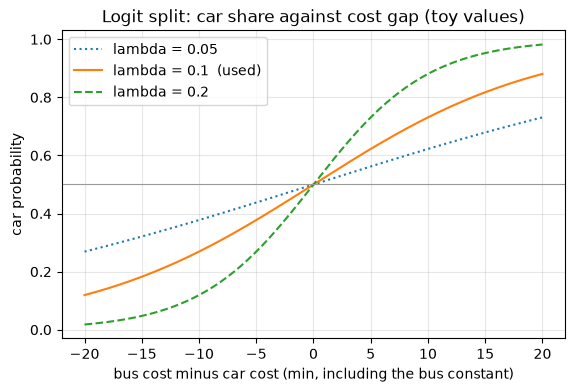

In [216]:
delta = np.linspace(-20, 20, 200)            # bus cost minus car cost, minutes (including the bus constant)
fig, ax = plt.subplots(figsize=(6.5, 4))
for lam_try, style in [(0.05, ":"), (lam, "-"), (0.2, "--")]:
    label = f"lambda = {lam_try}" + ("  (used)" if lam_try == lam else "")
    ax.plot(delta, 1 / (1 + np.exp(-lam_try * delta)), style, label=label)
ax.axhline(0.5, color="0.6", linewidth=0.8)
ax.set_xlabel("bus cost minus car cost (min, including the bus constant)")
ax.set_ylabel("car probability")
ax.set_title("Logit split: car share against cost gap (toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Split the trips.** Zero-car households can only use bus. Car-owning households split by the logit. Work and other trips use the same costs, λ and bus constant. Shopping may need its own calibration, which is a known simplification (see Notes).

$$T^{car,\,person}_{ij} = P^{car}_{ij} \, T^{own}_{ij} \qquad\qquad T^{bus}_{ij} = (1 - P^{car}_{ij}) \, T^{own}_{ij} + T^{zero}_{ij}$$

Each split must add back up to the total, which we check.

**TAG reference.** Not checked. Splitting by car availability is a segmentation choice. TAG's segmentation advice is in M2.1, to be located.

In [217]:
P_car_own = p_car(asc_bus)
T_car_person = P_car_own * T_own                     # person trips by car, work and other
T_bus = (1 - P_car_own) * T_own + T_zero             # person trips by bus, work and other

print("check: car + bus = all trips?", np.allclose(T_car_person + T_bus, T_all))
print("car person trips/h:", T_car_person.sum().round(1), "   bus trips/h:", T_bus.sum().round(1))
pd.DataFrame(T_car_person, index=ZONES, columns=ZONES).round(1)


check: car + bus = all trips? True
car person trips/h: 931.0    bus trips/h: 969.0


,A,B,C,D
A,203.4,51.2,32.4,55.1
B,123.0,63.5,49.6,34.1
C,46.8,27.6,69.0,52.8
D,36.8,9.4,33.7,42.5


### From trips to modes

All trips split into car-owning and zero-car households. Car-owning trips then split into car and bus. Arrow width shows the trips per hour.

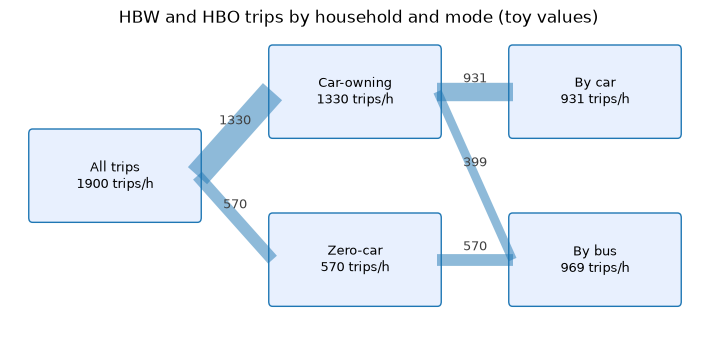

In [218]:
from matplotlib.patches import FancyBboxPatch

total_all = T_all.sum()
boxes = {
    "All trips": (0.0, 1.3, total_all),
    "Car-owning": (3.2, 2.2, T_own.sum()),
    "Zero-car": (3.2, 0.4, T_zero.sum()),
    "By car": (6.4, 2.2, T_car_person.sum()),
    "By bus": (6.4, 0.4, T_bus.sum()),
}
edges = [
    ("All trips", "Car-owning", T_own.sum()),
    ("All trips", "Zero-car", T_zero.sum()),
    ("Car-owning", "By car", T_car_person.sum()),
    ("Car-owning", "By bus", T_own.sum() - T_car_person.sum()),
    ("Zero-car", "By bus", T_zero.sum()),
]
fig, ax = plt.subplots(figsize=(9, 4))
for a_name, b_name, value in edges:
    xa, ya, _ = boxes[a_name]
    xb, yb, _ = boxes[b_name]
    ax.plot([xa + 2.2, xb], [ya + 0.45, yb + 0.45], color="tab:blue", alpha=0.5,
            linewidth=1 + 25 * value / total_all, solid_capstyle="butt")
    ax.text((xa + 2.2 + xb) / 2, (ya + yb) / 2 + 0.55, f"{value:.0f}", ha="center", fontsize=9, color="0.25")
for name, (x, y, total) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), 2.2, 0.9, boxstyle="round,pad=0.05",
                                facecolor="#e8f0fe", edgecolor="tab:blue"))
    ax.text(x + 1.1, y + 0.45, f"{name}\n{total:.0f} trips/h", ha="center", va="center", fontsize=9)
ax.set_xlim(-0.3, 9)
ax.set_ylim(0, 3.3)
ax.axis("off")
ax.set_title("HBW and HBO trips by household and mode (toy values)")
plt.show()

# Level 4: assignment

Car trips now go onto the roads. Two new ideas:

1. **Person trips to vehicles.** A car carries several people, so the network needs vehicles, not persons.
2. **Congestion.** Each trip takes its cheapest route, and the route gets slower as it fills up. We solve this with the method of successive averages (MSA).

**Simplifying:** each trip takes the quickest route for the current times, and vehicles are person trips divided by an average occupancy.

**Adding:** road capacity and congestion, so travel times rise as flows approach capacity.

**Why:** car trips use real roads, and congestion means routes and times depend on how many vehicles use them.


## Part J. Vehicles, routes and congestion

**First principles.** A trip follows a **path**: a sequence of links from its origin to its destination. Each trip takes the path with the least time. Roads slow down as they fill up, so the times depend on the flows and the flows depend on the times.

**Occupancy.** A car carries several people. Dividing person trips by the number of people per car gives vehicle trips:

$$V^{car}_{ij} = \frac{T^{car,\,person}_{ij}}{\text{occupancy}}$$

We use 1.1 persons per car as a placeholder. The plan (Phase 4) says to take it from TAG; M2.1 gives the advice on occupancy factors.

**Three steps for the network:**

1. **List the paths.** For each origin–destination pair, list every route that does not visit a zone twice.
2. **All-or-nothing (AON).** Load each pair's demand onto its cheapest path. This ignores congestion, so it is a starting point.
3. **Congestion (BPR).** A road's time rises with its flow relative to its capacity:

$$t_a = t^0_a \left(1 + \alpha \left(\frac{v_a}{\text{cap}_a}\right)^{\beta}\right), \qquad \alpha = 0.15, \quad \beta = 4$$

The power of 4 keeps the increase small when a road is half-full, and makes it jump near capacity.

**TAG reference: M2.2 section 5.4.4, PDF p. 28.**
> "Car occupancy is generally expected to vary by factors such as trip purpose, travel time, trip distance, and area type."

The occupancy of 1.1 is a placeholder. The data book, Table A1.3.3, gives 1.11 for work trips (weekday average, 2010 values). TAG unit M2.1 gives the advice on car occupancy factors.

**TAG reference: M3.1 section 2.9, PDF p. 23.**
> "The speed/flow relationships recommended for use in highway assignment models are specified in Appendix E:."

BPR is not the form TAG specifies. The alpha = 0.15 and beta = 4 here are our choice, so either use Appendix E or justify BPR.

In [219]:
occupancy = 1.1   # persons per car (placeholder)

V_car = T_car_person / occupancy   # vehicles per hour
np.fill_diagonal(V_car, 0.0)       # intrazonal trips do not use the network

print("car vehicles/h on the network:", V_car.sum().round(1))

car vehicles/h on the network: 502.3


In [220]:
# Adjacency: for each zone, the zones it links to and the link index.
adj = {z: [] for z in ZONES}
for k, row in links.iterrows():
    adj[row["from"]].append((row["to"], k))
    adj[row["to"]].append((row["from"], k))

def simple_paths(o, d, path=None, used=None):
    """All paths from zone o to zone d that never visit a zone twice.
    Returns a list of (zones, link_indices)."""
    path = [o] if path is None else path
    used = [] if used is None else used
    if path[-1] == d:
        return [(path, used)]
    found = []
    for nxt, k in adj[path[-1]]:
        if nxt not in path:
            found += simple_paths(o, d, path + [nxt], used + [k])
    return found

paths = {(o, d): simple_paths(o, d) for o in ZONES for d in ZONES if o != d}

for zones, _ in paths[("A", "C")]:
    print(" -> ".join(zones))

A -> B -> C
A -> D -> C
A -> C


In [221]:
alpha, beta_bpr = 0.15, 4
cap = links["capacity_vph"].to_numpy(dtype=float)
t0 = links["free_flow_min"].to_numpy(dtype=float)

def bpr(flow):
    """Link travel time (min) for a given flow (veh/h) on each link."""
    return t0 * (1 + alpha * (flow / cap) ** beta_bpr)

def all_or_nothing(demand, link_time):
    """Load each OD demand onto its cheapest path. Returns link flows (veh/h)."""
    flows = np.zeros(len(links))
    for (o, d), plist in paths.items():
        q = demand[idx[o], idx[d]]
        if q == 0:
            continue
        cheapest = min(plist, key=lambda p: sum(link_time[k] for k in p[1]))
        for k in cheapest[1]:
            flows[k] += q
    return flows

## Part K. Method of successive averages

**First principles.** Flows change times, and times change flows. MSA handles this by moving only part of the way towards each new all-or-nothing answer:

1. With the current flows $x$, compute the link times $t$ with BPR.
2. Load the demand by AON on those times. This gives a target flow $y$.
3. Move part of the way towards $y$: $x_{\text{new}} = x + \frac{1}{k}(y - x)$. The step $1/k$ shrinks each time, so the flows settle.
4. Measure the **relative gap**. This compares the average time the current flows take with the time the cheapest routes would take:

$$\text{gap} = \frac{\sum_a x_a t_a - \sum_a y_a t_a}{\sum_a x_a t_a}$$

Near zero means no one would gain by switching route. We stop when the gap is below 0.1%, the same tolerance as the Furness step.

Frank–Wolfe, which chooses the step size with a line search, is a later step in the plan (Phase 5.3). It is not used here.

**TAG reference: M3.1 section Table 4, PDF p. 37.**
> "Less than 0.1% or at least stable with convergence fully documented and all other criteria met"

Our stopping rule (relative gap below 0.1%) matches TAG's base-model convergence value.

**TAG reference: M3.1 section 3.4, PDF p. 34.**
> "some methods such as the Method of Successive Averages (MSA) force it to happen, without there necessarily being convergence to a solution."

Stable flows alone do not show convergence. The gap test is what shows it, which is why this notebook uses it.

In [222]:
def msa(demand, tol=1e-3, max_iter=50):
    """Method of successive averages on the vehicle demand. Stops when the gap is below tol."""
    x = all_or_nothing(demand, t0)                 # iteration 1: free-flow times
    gaps = []                                      # gap at each iteration, for the convergence chart
    for k in range(2, max_iter + 1):
        t = bpr(x)                                  # times at the current flows
        y = all_or_nothing(demand, t)               # cheapest routes at those times
        gap = (np.sum(x * t) - np.sum(y * t)) / np.sum(x * t)
        print(f"iteration {k-1:2d}: gap {gap:.5f}   flows {x.round(0)}")
        gaps.append(gap)
        if gap < tol:
            break
        x = x + (y - x) / k                         # step size 1/k
    return x, gap, gaps

flows, final_gap, gap_history = msa(V_car, tol=1e-3)
print()
print("final gap:", round(final_gap, 5))

iteration  1: gap 0.00000   flows [158. 110. 118.  84.  72.]

final gap: 0.0


### MSA converging

The relative gap falls at each iteration. The notebook stops once it is below the red line (0.1%). This is the same tolerance as the Furness step.

C:\Users\Theo Cochrane\AppData\Local\Temp\ipykernel_27992\553815904.py:3: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.axhline(1e-3, color="tab:red", linestyle="--", label="tolerance 0.1%")


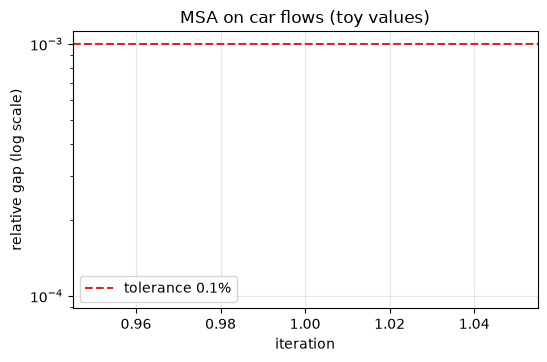

In [223]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogy(range(1, len(gap_history) + 1), gap_history, marker="o")
ax.axhline(1e-3, color="tab:red", linestyle="--", label="tolerance 0.1%")
ax.set_xlabel("iteration")
ax.set_ylabel("relative gap (log scale)")
ax.set_title("MSA on car flows (toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [224]:
t_final = bpr(flows)
result = links.assign(
    flow_vph=flows.round(0),
    time_min=t_final.round(2),
    v_over_c=(flows / cap).round(2),
)
result

,from,to,free_flow_min,capacity_vph,flow_vph,time_min,v_over_c
0,A,B,10,150,158.0,11.86,1.06
1,B,C,12,125,110.0,13.07,0.88
2,C,D,8,250,118.0,8.06,0.47
3,D,A,15,150,84.0,15.22,0.56
4,A,C,20,100,72.0,20.81,0.72


### Flows on the map

Left: all-or-nothing loading at free-flow times. Right: the final flows after the MSA loop, at congested times. Line width is flow, on one scale for both panels.

On these toy values the two panels are the same. Every zone pair has one clear cheapest route, so no trip changes route when times rise, and MSA stops after one iteration. Congestion still raises link times (see the congestion curve above), but it does not move flows here. Changing the network or the capacities would be needed to show a shift.

In [ ]:
from matplotlib.patches import Rectangle

aon_flows = all_or_nothing(V_car, t0)
top = max(aon_flows.max(), flows.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, f, title in [(axes[0], aon_flows, "All-or-nothing, free-flow times"),
                     (axes[1], flows, "After MSA, congested times")]:
    for z, (x, y) in zone_corner.items():
        ax.add_patch(Rectangle((x, y), W, H, facecolor="#eef4fb", edgecolor="0.6", linewidth=0.8, zorder=0))
    for k, row in links.iterrows():
        (x1, y1), (x2, y2) = pos[row["from"]], pos[row["to"]]
        ax.plot([x1, x2], [y1, y2], color="tab:blue", alpha=0.55,
                linewidth=0.5 + 10 * f[k] / top, solid_capstyle="round", zorder=2)
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        dx, dy = mx - centre[0], my - centre[1]
        norm = np.hypot(dx, dy)
        if norm > 0:
            mx, my = mx + 0.6 * dx / norm, my + 0.6 * dy / norm
        ax.text(mx, my, f"{row['from']}-{row['to']}\n{f[k]:.0f} veh/h", ha="center", va="center",
                fontsize=8, zorder=4, bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
    for z, (x, y) in pos.items():
        ax.scatter(x, y, s=400, color="tab:blue", zorder=3)
        ax.text(x, y, z, color="white", ha="center", va="center", fontsize=11, weight="bold", zorder=5)
    ax.set_aspect("equal")
    ax.set_xlim(-1.5, 9.5)
    ax.set_ylim(-1.5, 7.5)
    ax.axis("off")
    ax.set_title(title)
fig.suptitle("Car vehicles on the toy network (toy values)")
plt.tight_layout()
plt.show()

### The congestion curve

The curve shows how much slower a link gets as its flow rises. The dots are our links at their final flows. This is the BPR form used in the notebook, not the form TAG specifies.

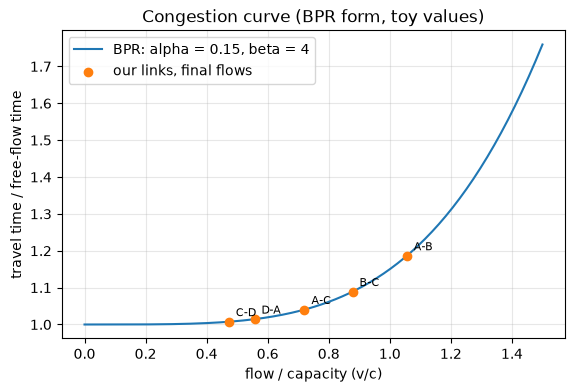

In [225]:
vc = np.linspace(0, 1.5, 200)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(vc, 1 + alpha * vc ** beta_bpr, label=f"BPR: alpha = {alpha}, beta = {beta_bpr}")
ratio = t_final / t0
ax.scatter(flows / cap, ratio, color="tab:orange", zorder=3, label="our links, final flows")
for k, row in links.iterrows():
    ax.annotate(f"{row['from']}-{row['to']}", (flows[k] / cap[k], ratio[k]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("flow / capacity (v/c)")
ax.set_ylabel("travel time / free-flow time")
ax.set_title("Congestion curve (BPR form, toy values)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Level 5: validation

The model is only useful if it matches something real. We compare it with counts and journey times that it was not tuned to. Three checks:

1. **Link flows, GEH.** Compare each link's flow with its count.
2. **Screenlines.** Compare the total crossing a line of links, which tests the overall movement pattern.
3. **Journey times.** Compare the travel time between pairs of zones with observed times.

The counts and journey times below are **made up**, for practice only. In the plan they come from DfT counts and Google Routes API benchmarks.

**Simplifying:** the checks use made-up counts and journey times, so the results show the method, not Salisbury.

**Adding:** the tests that compare the model with observed data: GEH on link flows, screenlines, journey times, and a pass or fail summary.

**Why:** a model that has not been compared with observed data cannot be trusted for forecasts.


## Part L. Link flows: GEH

**First principles.** Compare the modelled flow $M$ with the counted flow $C$ on each link, using the **GEH** statistic:

$$\text{GEH} = \sqrt{\frac{2\,(M - C)^2}{M + C}}$$

A 50-vehicle error matters more on a quiet road than on a busy one. Dividing by the average flow makes roads of any size comparable.

**TAG-style pass rule** (see the plan, Phase 6.3): GEH below 5 on at least 85% of the counted links. A single link above 5 is not a failure on its own. The share is what counts.

**TAG reference: M3.1 section 3.3.11, PDF p. 31.**
> "flows that meet either criterion should be regarded as satisfactory."

TAG accepts a link flow that meets either GEH or the absolute and percentage criteria. Our check uses GEH only, which is stricter.

**TAG reference: M3.1 section Table 2, PDF p. 32.**
> "GEH < 5 for individual flows"

The guideline is that more than 85% of cases meet it, which matches the rule in this notebook.

**Known result, not a bug.** The counts in this notebook are made up, and the model flows do not match them well enough for 85% of links to pass the GEH test. At the moment 80% pass, so this check fails (see Part N). The model numbers are not tuned to pass it. The failure is kept on purpose: it shows what the check catches. Replace the counts with observed ones before judging the model.


In [226]:
def geh(M, C):
    return np.sqrt(2 * (M - C) ** 2 / (M + C))

# Made-up counts (veh/h), keyed by link so the order cannot go wrong.
# The A to C count is set well below the model, so the GEH check fails on that link.
counted = {("A", "B"): 150.0, ("B", "C"): 130.0, ("C", "D"): 120.0, ("D", "A"): 106.0, ("A", "C"): 30.0}
counts = np.array([counted[(r["from"], r["to"])] for _, r in links.iterrows()])

check_links = links.assign(
    modelled=flows.round(0),
    counted=counts,
    geh=geh(flows, counts).round(2),
    geh_below_5=geh(flows, counts) < 5,
)
check_links

,from,to,free_flow_min,capacity_vph,modelled,counted,geh,geh_below_5
0,A,B,10,150,158.0,150.0,0.67,True
1,B,C,12,125,110.0,130.0,1.85,True
2,C,D,8,250,118.0,120.0,0.16,True
3,D,A,15,150,84.0,106.0,2.31,True
4,A,C,20,100,72.0,30.0,5.89,False


In [227]:
share_passing = check_links["geh_below_5"].mean()
print(f"links with GEH < 5: {share_passing:.0%}   (pass rule: at least 85%)")
print("GEH pass:", share_passing >= 0.85)

links with GEH < 5: 80%   (pass rule: at least 85%)
GEH pass: False


## Part M. Screenlines and journey times

**Screenline.** A screenline is an imaginary line across the study area. Sum the flows on every link that crosses it, and compare the model with the counts. Here the line separates zones {A, B} from zones {C, D}. Plan Phase 6.2 asks for a total within 5%.

**Journey times.** For each pair of zones, the modelled time is the quickest path time at the final flows. The plan's rule is: within 15% of observed, or within 1 minute if that is larger, on at least 85% of routes.

**TAG reference: M2.2 section 6.2.23, PDF p. 34.**
> "TAG units M3.1 and M3.2 set out flow criteria at screenline level for highway (i.e. ±5%) and public transport (i.e. ±15%) matrices, respectively."

The screenline test uses the highway ±5%, which matches TAG.

**TAG reference: M3.1 section Table 3, PDF p. 33.**
> "Modelled times along routes should be within 15% of surveyed times (or 1 minute, if higher than 15%)"

The journey-time rule matches TAG Table 3: more than 85% of routes.

In [228]:
# Links crossing the line between {A, B} and {C, D}, found from the zone sets.
side_1 = {"A", "B"}
crossing = [k for k, r in links.iterrows() if (r["from"] in side_1) != (r["to"] in side_1)]
counted_screenline = counts[crossing].sum()
modelled_screenline = flows[crossing].sum()
screen_error = modelled_screenline / counted_screenline - 1

print(f"screenline modelled {modelled_screenline:.0f} vs counted {counted_screenline:.0f}  "
      f"({screen_error:+.1%}, pass if within 5%)")

screenline modelled 265 vs counted 266  (-0.3%, pass if within 5%)


### The screenline on the map

The dashed line separates {A, B} from {C, D}. The orange links cross it. Their flows are summed for the screenline check above.

In [ ]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for z, (x, y) in zone_corner.items():
    ax.add_patch(Rectangle((x, y), W, H, facecolor="#eef4fb", edgecolor="0.6", linewidth=0.8, zorder=0))
for k, row in links.iterrows():
    (x1, y1), (x2, y2) = pos[row["from"]], pos[row["to"]]
    is_cross = k in crossing
    ax.plot([x1, x2], [y1, y2], color="tab:orange" if is_cross else "0.7",
            linewidth=2.5 if is_cross else 1.5, zorder=2)
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    dx, dy = mx - centre[0], my - centre[1]
    norm = np.hypot(dx, dy)
    if norm > 0:
        mx, my = mx + 0.6 * dx / norm, my + 0.6 * dy / norm
    ax.text(mx, my, f"{row['from']}-{row['to']}", ha="center", va="center", fontsize=8, zorder=4,
            color="tab:orange" if is_cross else "0.3",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
for z, (x, y) in pos.items():
    ax.scatter(x, y, s=400, color="tab:blue", zorder=3)
    ax.text(x, y, z, color="white", ha="center", va="center", fontsize=11, weight="bold", zorder=5)
ax.plot([-0.5, 8.5], [3, 3], color="tab:red", linestyle="--", linewidth=1.5, zorder=1)
ax.text(8.4, 3.12, "screenline", color="tab:red", fontsize=9, ha="right", va="bottom")
ax.text(-0.3, 3.12, "{A, B}", fontsize=9, color="0.3", ha="left", va="bottom")
ax.text(-0.3, 2.88, "{C, D}", fontsize=9, color="0.3", ha="left", va="top")
ax.set_aspect("equal")
ax.set_xlim(-1.5, 9.5)
ax.set_ylim(-1.5, 7.5)
ax.axis("off")
ax.set_title(f"Screenline: {len(crossing)} links cross it (orange)")
plt.show()

In [229]:
def min_path_time(o, d, link_time):
    """Quickest path time from zone o to zone d, using the given link times."""
    return min(sum(link_time[k] for k in p[1]) for p in paths[(o, d)])

# Made-up observed journey times (min) for three routes.
observed = {("A", "C"): 22.0, ("B", "D"): 24.0, ("C", "A"): 22.0}

rows = []
for (o, d), obs in observed.items():
    mod = min_path_time(o, d, t_final)
    within = abs(mod - obs) <= max(0.15 * obs, 1.0)
    rows.append({"route": f"{o} to {d}", "modelled": round(mod, 1), "observed": obs,
                 "within rule": within})
journey = pd.DataFrame(rows)
journey

,route,modelled,observed,within rule
0,A to C,20.8,22.0,True
1,B to D,21.1,24.0,True
2,C to A,20.8,22.0,True


### Validation charts

Left: GEH. Each dot is a link. Dots between the two curves pass (GEH below 5). Middle: the screenline total against the counts, with the ±5% band. Right: journey times, with the 15% (or 1 minute) band.

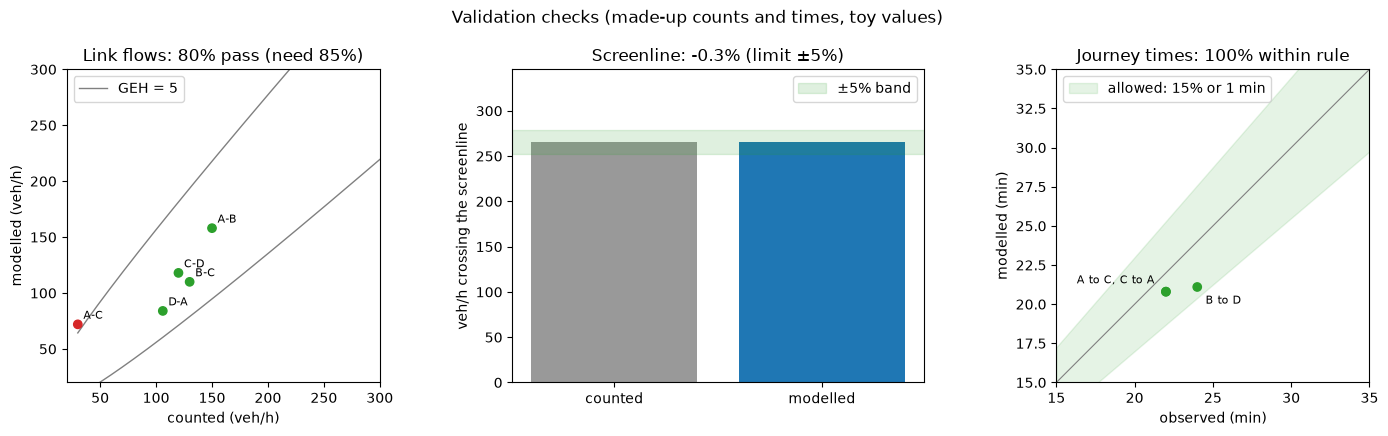

In [230]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# Left: GEH. The curves mark GEH = 5, from 2(M - C)^2 / (M + C) = 25.
ax = axes[0]
M = check_links["modelled"].to_numpy(float)
C = check_links["counted"].to_numpy(float)
Cl = np.linspace(30, 300, 200)
root = np.sqrt(625 + 400 * Cl)
ax.plot(Cl, Cl + (25 + root) / 4, color="0.5", linewidth=1)
ax.plot(Cl, Cl + (25 - root) / 4, color="0.5", linewidth=1, label="GEH = 5")
colours = np.where(check_links["geh_below_5"].to_numpy(), "tab:green", "tab:red")
ax.scatter(C, M, c=colours, zorder=3)
for k in range(len(links)):
    ax.annotate(f"{links.loc[k, 'from']}-{links.loc[k, 'to']}", (C[k], M[k]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlim(20, 300)
ax.set_ylim(20, 300)
ax.set_aspect("equal")
ax.set_xlabel("counted (veh/h)")
ax.set_ylabel("modelled (veh/h)")
ax.set_title(f"Link flows: {share_passing:.0%} pass (need 85%)")
ax.legend(loc="upper left")

# Middle: screenline total against the counts, with the 5% band
ax = axes[1]
ax.bar(["counted", "modelled"], [counted_screenline, modelled_screenline], color=["0.6", "tab:blue"])
ax.axhspan(counted_screenline * 0.95, counted_screenline * 1.05, color="tab:green", alpha=0.15,
           label="±5% band")
ax.set_ylim(0, counted_screenline * 1.3)
ax.set_ylabel("veh/h crossing the screenline")
ax.set_title(f"Screenline: {screen_error:+.1%} (limit ±5%)")
ax.legend(loc="upper right")

# Right: journey times, with the allowed band
ax = axes[2]
obs = journey["observed"].to_numpy(float)
mod = journey["modelled"].to_numpy(float)
ok = journey["within rule"].to_numpy(bool)
ax.scatter(obs, mod, c=np.where(ok, "tab:green", "tab:red"), zorder=3)
same_point = {}                                  # routes with the same observed and modelled time share one label
for o, m, r in zip(obs, mod, journey["route"]):
    same_point.setdefault((o, m), []).append(r)
for (o, m), names in same_point.items():
    if "B to D" in names:
        ax.annotate(", ".join(names), (o, m), textcoords="offset points", xytext=(6, -12), fontsize=8, ha="left")
    else:
        ax.annotate(", ".join(names), (o, m), textcoords="offset points", xytext=(-8, 6), fontsize=8, ha="right")
xs = np.linspace(15, 35, 50)
allowed = np.maximum(0.15 * xs, 1.0)
ax.fill_between(xs, xs - allowed, xs + allowed, color="tab:green", alpha=0.12,
                label="allowed: 15% or 1 min")
ax.plot([15, 35], [15, 35], color="0.5", linewidth=0.8)
ax.set_xlim(15, 35)
ax.set_ylim(15, 35)
ax.set_aspect("equal")
ax.set_xlabel("observed (min)")
ax.set_ylabel("modelled (min)")
ax.set_title(f"Journey times: {journey['within rule'].mean():.0%} within rule")
ax.legend(loc="upper left")

fig.suptitle("Validation checks (made-up counts and times, toy values)")
plt.tight_layout()
plt.show()

## Part N. Summary of checks

One table with the pass rules, so you can see at a glance what the model meets and what it does not.

In [231]:
summary = pd.DataFrame(
    [
        ("Link flows (GEH < 5)", f"{share_passing:.0%} of links", "at least 85%", share_passing >= 0.85),
        ("Screenline total", f"{screen_error:+.1%}", "within 5%", abs(screen_error) <= 0.05),
        ("Journey times", f"{journey['within rule'].mean():.0%} of routes", "at least 85%",
         journey["within rule"].mean() >= 0.85),
    ],
    columns=["check", "result", "rule", "passes"],
)
summary

,check,result,rule,passes
0,Link flows (GEH < 5),80% of links,at least 85%,False
1,Screenline total,-0.3%,within 5%,True
2,Journey times,100% of routes,at least 85%,True


### Checks the notebook reports (GEH is expected to fail for now)

These checks run every time. They confirm the arithmetic is right, and that the made-up data fails exactly the GEH test, as intended.

In [232]:
# Trip totals: each zone's row and column totals match the targets (Furness converges to 0.1%).
assert np.allclose(T_w.sum(axis=1), P_w, rtol=2e-3), "HBW row totals must equal productions"
assert np.allclose(T_w.sum(axis=0), A_w, rtol=2e-3), "HBW column totals must equal attractions"
assert np.allclose(T_o.sum(axis=1), P_o), "HBO row totals must equal productions (singly constrained)"

# Splits add back to the total.
assert np.allclose(T_own + T_zero, T_all), "car-owning + zero-car must equal all trips"
assert np.allclose(T_car_person + T_bus, T_all), "car + bus must equal all trips"

# Vehicles: person trips divided by occupancy, with the diagonal (intrazonal) removed.
assert np.isclose(V_car.sum(), (T_car_person.sum() - np.trace(T_car_person)) / occupancy), \
    "vehicles must equal car person trips / occupancy, off the diagonal"
assert np.all(flows >= 0), "link flows cannot be negative"

# The made-up data is set to fail the GEH test only, so the summary is a real test.
assert share_passing < 0.85, "GEH should fail on the made-up data (by design)"
assert screen_error <= 0.05 and journey["within rule"].mean() >= 0.85, "screenline and journey times should pass"
print("All checks passed.")

All checks passed.


## Notes

Write down anything that surprised you, and what you would check first if the numbers looked wrong.

Things to record as the model is developed:

- Every placeholder value above (β, λ, occupancy, value of time, fares, walk and wait weights, zero-car share, observed car share, counts, and journey times) is made up. Each one should be replaced with a sourced value, and the source logged in `docs/methodology.md`.
- The bus constant is calibrated to a made-up car share. Its value only means something once the target comes from data.
- Work and other trips share one set of generalised costs, one λ and one bus constant. Shopping may need its own calibration.
- Congestion does not feed back into trip distribution. Distribution uses free-flow times only (a possible later level).

**TAG references.** Each decision is referenced in its Part above, with a status in `docs/methodology.md`. Statuses: matches TAG, outside TAG range, not in TAG, placeholder, or not checked.